# Ejercicio 2 - Predicción de Abandono de Clientes (Customer Churn)
## Empresa de Telecomunicaciones - Telco Customer Churn Dataset

**Objetivo:** construir y comparar 5 modelos de clasificación supervisada (Logistic Regression, KNN, SVM, Decision Tree y Naive Bayes) para predecir qué clientes abandonarán la empresa (`Churn = Yes`), seleccionar el mejor con justificación técnica y estadística, y usarlo en un sistema de predicción de nuevos clientes.

**Dataset:** [Telco Customer Churn (Kaggle, blastchar)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). Se carga desde el mirror público de IBM (es el mismo archivo), así el cuaderno corre en Colab sin credenciales de Kaggle.

**Cómo leer este cuaderno:** cada sección empieza con una explicación de qué se hace y por qué. Los valores numéricos citados en el texto corresponden a la ejecución guardada; si se vuelve a ejecutar en otra versión de las librerías, algunos pueden variar levemente (ver la nota en la sección 6.1).

### Contenido
1. Configuración del entorno
2. Comprensión del negocio
3. Carga de datos
4. Análisis exploratorio de datos (EDA)
5. Preprocesamiento (limpieza, codificación, escalamiento, división y balanceo)
6. Entrenamiento y evaluación de modelos
7. Fortalezas y debilidades de cada modelo
8. Validación estadística: ANOVA, Friedman y comparaciones por pares
9. Selección del mejor modelo, interpretación y calibración
10. Sistema de predicción de nuevos clientes
11. Preguntas de interpretación de métricas
12. Preguntas de análisis crítico
13. Conclusiones empresariales y limitaciones
14. Despliegue web (Streamlit)

## 1. Configuración del entorno
Colab ya trae `scikit-learn`, `scipy`, `pandas`, `matplotlib` y `seaborn`. Además, este cuaderno usa dos librerías extra:
- **`imbalanced-learn`**: aporta **SMOTENC**, la técnica para balancear las clases cuando hay variables numéricas y categóricas (sección 5.5).
- **`statsmodels`**: aporta la corrección de Holm para comparaciones múltiples (sección 8.6).

La siguiente celda revisa si cada una ya está instalada y **solo instala las que falten**. Como Colab normalmente ya las trae, lo habitual es que no instale nada y que no haga falta reiniciar el entorno.

In [1]:
# Revisa las librerías extra e instala solo las que falten
import importlib.util
import subprocess
import sys

for paquete, modulo in [("imbalanced-learn", "imblearn"), ("statsmodels", "statsmodels")]:
    if importlib.util.find_spec(modulo) is None:
        print(f"Instalando {paquete}...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)
    else:
        print(f"{paquete}: ya está instalado")

imbalanced-learn: ya está instalado
statsmodels: ya está instalado


In [2]:
# Librerías generales
import warnings
warnings.filterwarnings("ignore")

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Estadística
from scipy.stats import f_oneway, friedmanchisquare, levene, shapiro
from scipy.stats import t as distribucion_t
from statsmodels.stats.multitest import multipletests

# Machine Learning
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, brier_score_loss, confusion_matrix,
                             classification_report, roc_curve, ConfusionMatrixDisplay)

# Balanceo de clases
from imblearn.over_sampling import SMOTE, SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
print("Librerías cargadas correctamente")

Librerías cargadas correctamente


## 2. Comprensión del Negocio

### 2.1 ¿Por qué es importante predecir el abandono de clientes?

- **Retener suele costar menos que adquirir.** En telecomunicaciones, conseguir un cliente nuevo implica publicidad, comisiones de venta, subsidio de equipos e instalación. Conservar a un cliente actual normalmente es más barato.
- **Permite pasar de una gestión reactiva a una proactiva.** Si la empresa se entera del abandono cuando el cliente ya pidió la baja, casi siempre es tarde. Un modelo predictivo detecta la señal de riesgo *antes* y da tiempo para actuar.
- **Prioriza recursos limitados.** No se puede llamar ni ofrecer descuentos a los 7.043 clientes. El modelo ordena a los clientes por probabilidad de abandono para concentrar el esfuerzo en quienes están en mayor riesgo.
- **Ayuda a entender qué perfiles abandonan más.** Variables como tipo de contrato, permanencia, soporte técnico o método de pago muestran qué características están **asociadas** al abandono. Esto orienta dónde investigar, aunque por sí solo no demuestra causas.
- **En este dataset el problema es grande:** el **26,5 %** de los clientes abandonó (ver EDA), es decir, 1 de cada 4.

### 2.2 ¿Qué impacto económico tiene el churn?

- **Menos ingresos recurrentes:** cada cliente que se va deja de pagar su factura mensual. En este dataset, los clientes que abandonaron concentraban una parte de la facturación mensual mayor que su proporción de clientes (se cuantifica en la sección 4.7).
- **Pérdida del valor de vida del cliente (CLV):** no solo se deja de recibir la factura de un mes, sino los ingresos futuros que ese cliente habría generado si se quedaba.
- **Costo de adquisición no recuperado (CAC):** el dinero invertido en captar al cliente no se recupera si se va antes de tiempo, y hay que volver a gastar para reemplazarlo.
- **Efectos indirectos:** recomendaciones negativas (boca a boca), menos oportunidades de venta cruzada (*cross-selling*) y menor participación de mercado.

El dataset no incluye costos (de adquisición, de campañas o de servicio), así que en este trabajo solo se puede medir la **facturación asociada** a los clientes que abandonaron, no la pérdida económica neta.

### 2.3 ¿Cómo puede Machine Learning apoyar estrategias de marketing?

- **Segmentación por riesgo:** el modelo asigna a cada cliente una probabilidad de abandono, con la que se arman segmentos (riesgo alto, medio y bajo) para tratarlos de forma distinta.
- **Campañas focalizadas:** en vez de campañas masivas, marketing dirige ofertas a los clientes con mayor probabilidad de abandono, lo que reduce costos y mejora la tasa de respuesta.
- **Ofertas según el perfil:** si el riesgo está asociado a un contrato mes a mes, se puede ofrecer migrar a un contrato anual. Si está asociado a la falta de soporte técnico, se puede ofrecer soporte por unos meses.
- **Optimización del presupuesto:** combinando la probabilidad de abandono con el valor del cliente (factura mensual), se priorizan los clientes más valiosos con mayor riesgo.
- **Medición de resultados:** con pruebas A/B (grupo con oferta contra grupo de control) se mide si la campaña realmente redujo el abandono. Esto es necesario porque el modelo predice riesgo, pero no dice qué acción lo reduce.
- **Monitoreo continuo:** el modelo puede recalcular el riesgo cada mes y alertar cuando un cliente cambia de segmento.

### 2.4 ¿Qué departamentos de una empresa usarían este sistema?

| Departamento | Uso del sistema |
|---|---|
| **Marketing** | Diseñar campañas de retención y fidelización dirigidas a clientes de alto riesgo. |
| **Atención al cliente / Retención (call center)** | Priorizar llamadas proactivas y saber qué ofrecer a cada cliente. |
| **Ventas / Comercial** | Proponer mejoras de plan o migraciones a contratos de 1 o 2 años a clientes con riesgo. |
| **Finanzas** | Proyectar ingresos y evaluar si el costo de las campañas de retención se justifica. |
| **Producto y Servicio técnico** | Revisar los servicios asociados a más abandono (por ejemplo, fibra óptica sin soporte). |
| **Dirección / Business Intelligence** | Seguir indicadores (KPI) de churn y tomar decisiones estratégicas. |
| **TI / Ciencia de Datos** | Mantener, monitorear y reentrenar el modelo en producción. |

## 3. Carga de datos

In [3]:
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df_raw = pd.read_csv(URL)

print(f"Filas: {df_raw.shape[0]} | Columnas: {df_raw.shape[1]}")
df_raw.head()

Filas: 7043 | Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Diccionario de variables

| Grupo | Variables | Descripción |
|---|---|---|
| Identificación | `customerID` | ID del cliente (no aporta información predictiva). |
| Demográficas | `gender`, `SeniorCitizen`, `Partner`, `Dependents` | Género, adulto mayor, tiene pareja, tiene dependientes. |
| Tiempo de permanencia | `tenure` | Meses que el cliente lleva en la empresa. |
| Servicios contratados | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | Telefonía, internet (DSL / Fiber optic / No) y servicios adicionales. |
| Contrato y pago | `Contract`, `PaperlessBilling`, `PaymentMethod` | Tipo de contrato, factura electrónica y método de pago. |
| Facturación | `MonthlyCharges`, `TotalCharges` | Cargo mensual y cargo total acumulado. El dataset no indica la moneda, por eso en este cuaderno los montos se expresan en **unidades monetarias (u.m.)**. |
| **Objetivo** | **`Churn`** | **Yes** = el cliente abandonó, **No** = el cliente continúa. |

## 4. Análisis Exploratorio de Datos (EDA)
### 4.1 Estructura y tipos de datos

In [4]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### 4.2 Calidad de datos: nulos, duplicados y valores anómalos

In [5]:
print("Valores nulos por columna (NaN):", int(df_raw.isnull().sum().sum()))
print("Filas duplicadas:", df_raw.duplicated().sum())
print("customerID duplicados:", df_raw["customerID"].duplicated().sum())

# TotalCharges debería ser numérica pero se leyó como texto: hay valores en blanco
blancos = df_raw["TotalCharges"].astype(str).str.strip() == ""
print(f"\nTotalCharges en blanco: {blancos.sum()}")
print("tenure de esos clientes:", df_raw.loc[blancos, "tenure"].unique())
df_raw.loc[blancos, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Valores nulos por columna (NaN): 0
Filas duplicadas: 0
customerID duplicados: 0

TotalCharges en blanco: 11
tenure de esos clientes: [0]


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Hallazgo:** no hay `NaN` explícitos, pero `TotalCharges` llegó como texto porque tiene **11 valores en blanco** (cadenas vacías). Todos esos clientes tienen `tenure = 0`, es decir, son clientes nuevos que todavía no han acumulado facturación. Por eso su cargo total es 0. Se corrige en el preprocesamiento.

Para poder graficar, en el EDA se usa una copia con `TotalCharges` convertida a número.

In [6]:
df_eda = df_raw.copy()
df_eda["TotalCharges"] = pd.to_numeric(df_eda["TotalCharges"], errors="coerce").fillna(0)
df_eda["Churn_bin"] = (df_eda["Churn"] == "Yes").astype(int)
df_eda["SeniorCitizen"] = df_eda["SeniorCitizen"].map({0: "No", 1: "Yes"})

NUM_EDA = ["tenure", "MonthlyCharges", "TotalCharges"]
CAT_EDA = [c for c in df_eda.columns if c not in NUM_EDA + ["customerID", "Churn", "Churn_bin"]]
print("Numéricas  :", NUM_EDA)
print("Categóricas:", CAT_EDA)
df_eda[NUM_EDA].describe().round(2)

Numéricas  : ['tenure', 'MonthlyCharges', 'TotalCharges']
Categóricas: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


### 4.3 Distribución de la variable objetivo (Churn)

       Clientes      %
Churn                 
No         5174  73.46
Yes        1869  26.54


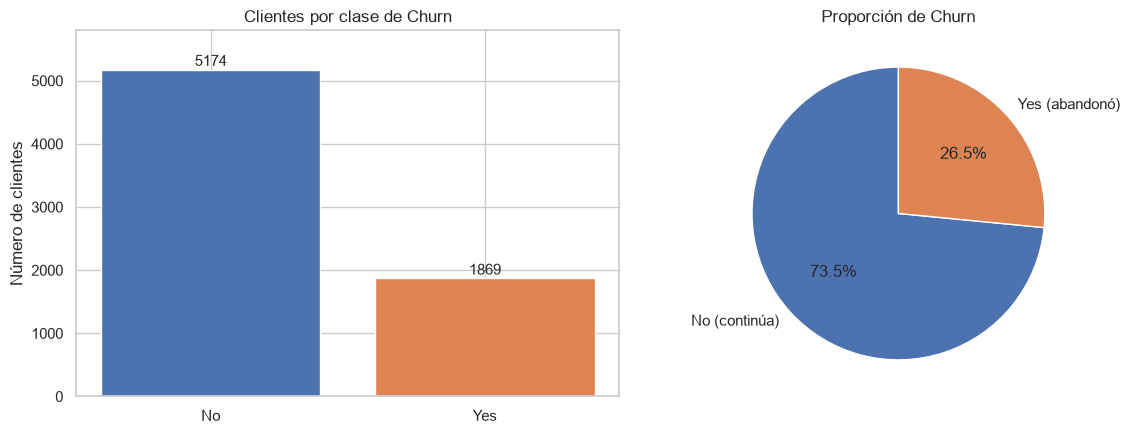

In [7]:
conteo = df_eda["Churn"].value_counts()
porcentaje = df_eda["Churn"].value_counts(normalize=True) * 100
print(pd.DataFrame({"Clientes": conteo, "%": porcentaje.round(2)}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colores = ["#4C72B0", "#DD8452"]
axes[0].bar(conteo.index, conteo.values, color=colores)
for i, v in enumerate(conteo.values):
    axes[0].text(i, v + 60, f"{v}", ha="center", fontsize=11)
axes[0].set_title("Clientes por clase de Churn")
axes[0].set_ylabel("Número de clientes")
axes[0].set_ylim(0, conteo.max() * 1.12)
axes[1].pie(conteo.values, labels=["No (continúa)", "Yes (abandonó)"], autopct="%1.1f%%",
            colors=colores, startangle=90, wedgeprops={"edgecolor": "white"})
axes[1].set_title("Proporción de Churn")
plt.tight_layout()
plt.show()

**Las clases están desbalanceadas:** 73,5 % *No* frente a 26,5 % *Yes* (aprox. 2,8 a 1). Un modelo que siempre prediga "No" tendría un Accuracy de 73,5 % sin detectar a ningún cliente que abandona. Por eso:
1. La división entrenamiento/prueba se hace **estratificada**.
2. Se **balancea** solo el conjunto de entrenamiento con **SMOTENC** (sección 5.5).
3. Se evalúa con **Recall, Precision, F1 y ROC-AUC** de la clase positiva (`Churn = Yes`), no solo con Accuracy.

### 4.4 Variables numéricas según Churn

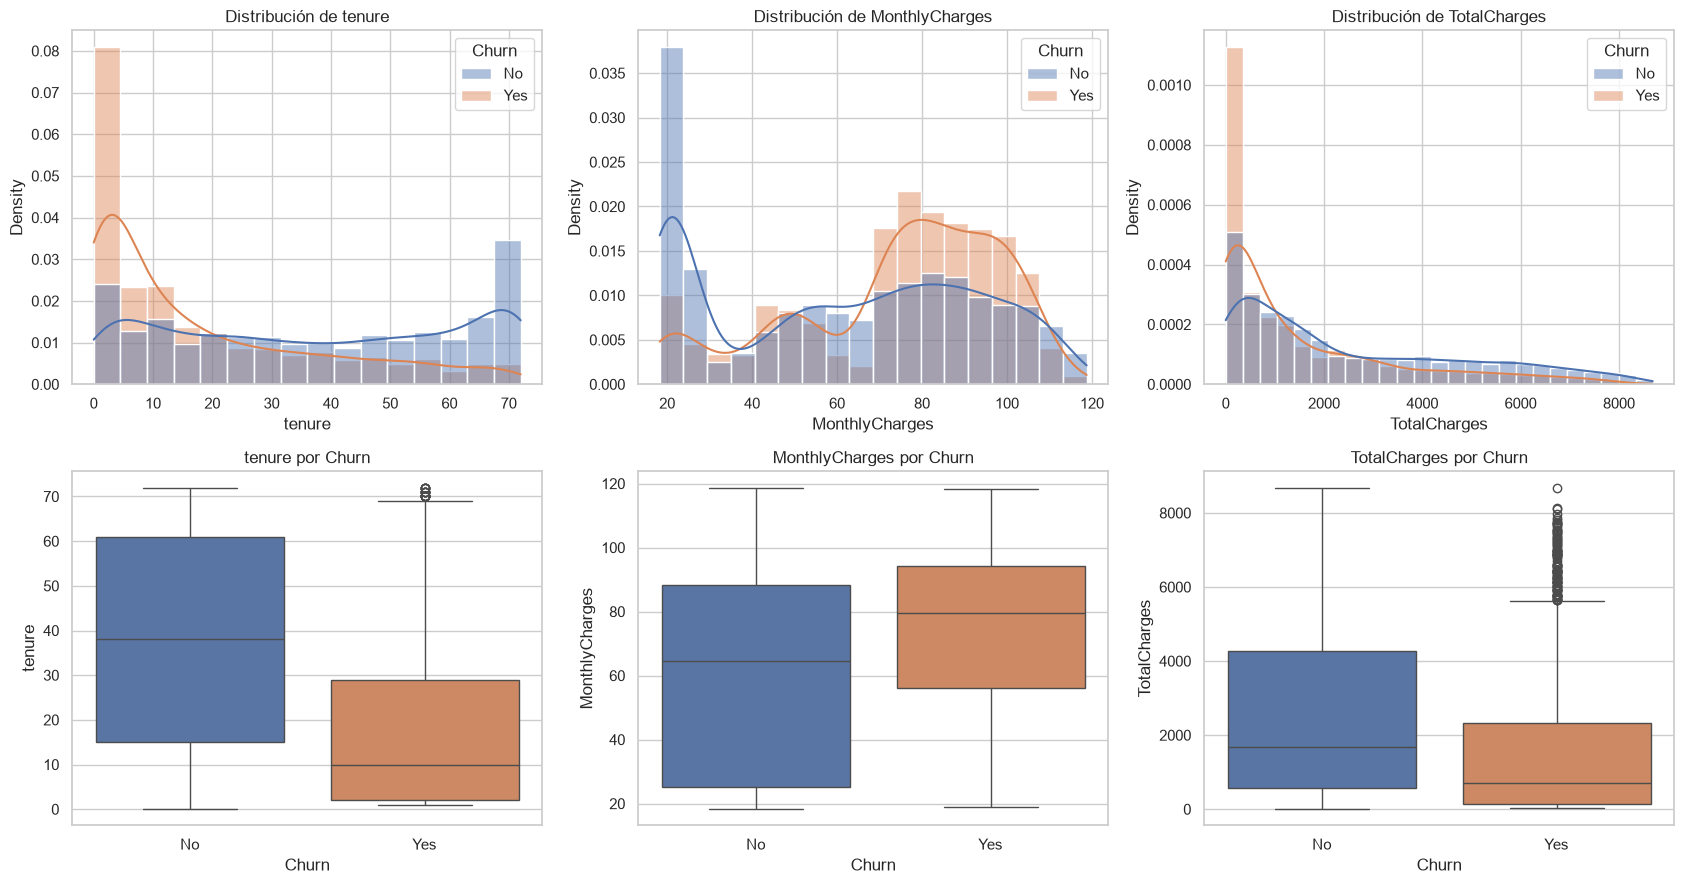

,tenure,MonthlyCharges,TotalCharges
Mediana por Churn,,,
No,38.0,64.43,1679.52
Yes,10.0,79.65,703.55


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for i, col in enumerate(NUM_EDA):
    sns.histplot(data=df_eda, x=col, hue="Churn", kde=True, stat="density",
                 common_norm=False, ax=axes[0, i], palette=colores, alpha=0.45)
    axes[0, i].set_title(f"Distribución de {col}")
    sns.boxplot(data=df_eda, x="Churn", y=col, ax=axes[1, i], palette=colores)
    axes[1, i].set_title(f"{col} por Churn")
plt.tight_layout()
plt.show()

df_eda.groupby("Churn")[NUM_EDA].median().round(2).rename_axis("Mediana por Churn")

### 4.5 Tasa de abandono por variable categórica
La línea roja punteada marca la tasa global de churn. Las barras por encima de esa línea son categorías con **mayor tasa de abandono que el promedio**.

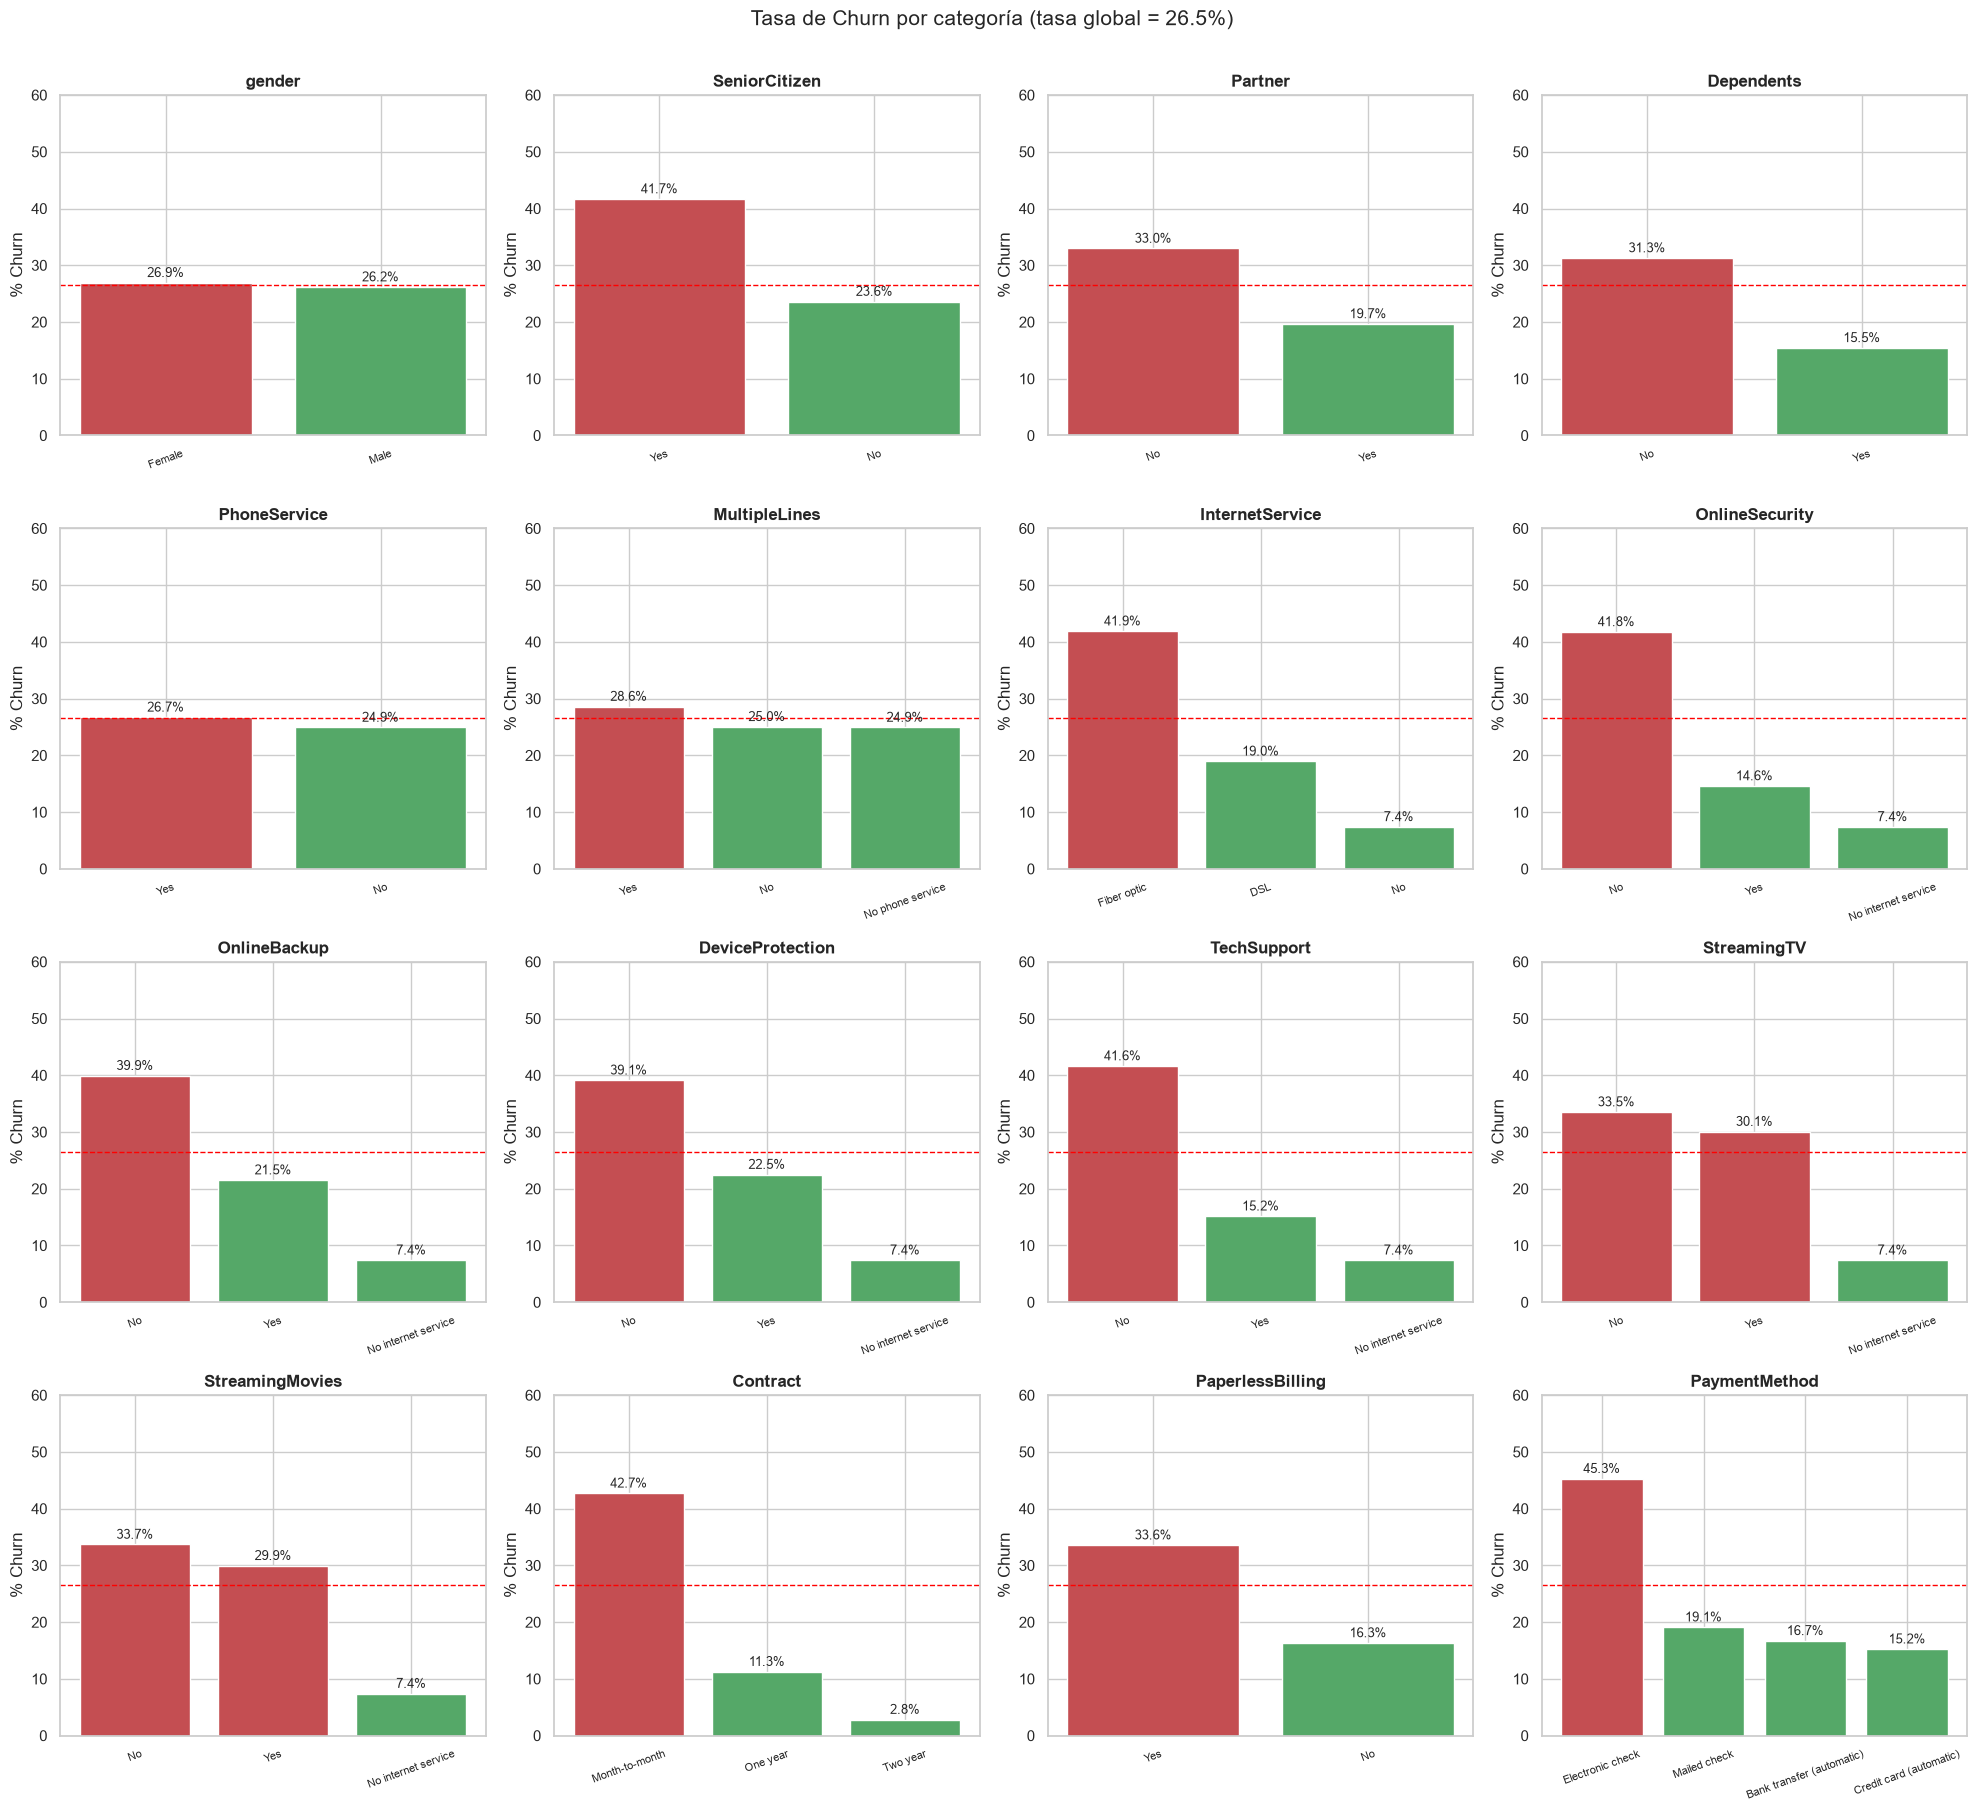

In [9]:
tasa_global = df_eda["Churn_bin"].mean() * 100
fig, axes = plt.subplots(4, 4, figsize=(20, 18))
for ax, col in zip(axes.ravel(), CAT_EDA):
    tasa = df_eda.groupby(col)["Churn_bin"].mean().sort_values(ascending=False) * 100
    barras = ax.bar(tasa.index.astype(str), tasa.values,
                    color=["#C44E52" if v > tasa_global else "#55A868" for v in tasa.values])
    ax.axhline(tasa_global, ls="--", color="red", lw=1)
    for b, v in zip(barras, tasa.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set_title(col, fontsize=12, fontweight="bold")
    ax.set_ylabel("% Churn")
    ax.set_ylim(0, 60)
    ax.tick_params(axis="x", rotation=20, labelsize=8)
plt.suptitle(f"Tasa de Churn por categoría (tasa global = {tasa_global:.1f}%)", fontsize=15, y=1.005)
plt.tight_layout()
plt.show()

In [10]:
# Ranking: ¿qué variables separan mejor a quienes abandonan? (diferencia entre la categoría de mayor y menor churn)
filas = []
for col in CAT_EDA:
    tasa = df_eda.groupby(col)["Churn_bin"].mean() * 100
    filas.append({"Variable": col,
                  "Categoría con más churn": tasa.idxmax(), "% churn (máx)": round(tasa.max(), 1),
                  "Categoría con menos churn": tasa.idxmin(), "% churn (mín)": round(tasa.min(), 1),
                  "Diferencia (pp)": round(tasa.max() - tasa.min(), 1)})
pd.DataFrame(filas).sort_values("Diferencia (pp)", ascending=False).reset_index(drop=True)

,Variable,Categoría con más churn,% churn (máx),Categoría con menos churn,% churn (mín),Diferencia (pp)
0,Contract,Month-to-month,42.7,Two year,2.8,39.9
1,InternetService,Fiber optic,41.9,No,7.4,34.5
2,OnlineSecurity,No,41.8,No internet service,7.4,34.4
3,TechSupport,No,41.6,No internet service,7.4,34.2
4,OnlineBackup,No,39.9,No internet service,7.4,32.5
5,DeviceProtection,No,39.1,No internet service,7.4,31.7
6,PaymentMethod,Electronic check,45.3,Credit card (automatic),15.2,30.0
7,StreamingMovies,No,33.7,No internet service,7.4,26.3
8,StreamingTV,No,33.5,No internet service,7.4,26.1
9,SeniorCitizen,Yes,41.7,No,23.6,18.1


### 4.6 Permanencia (tenure) por tramos y correlaciones

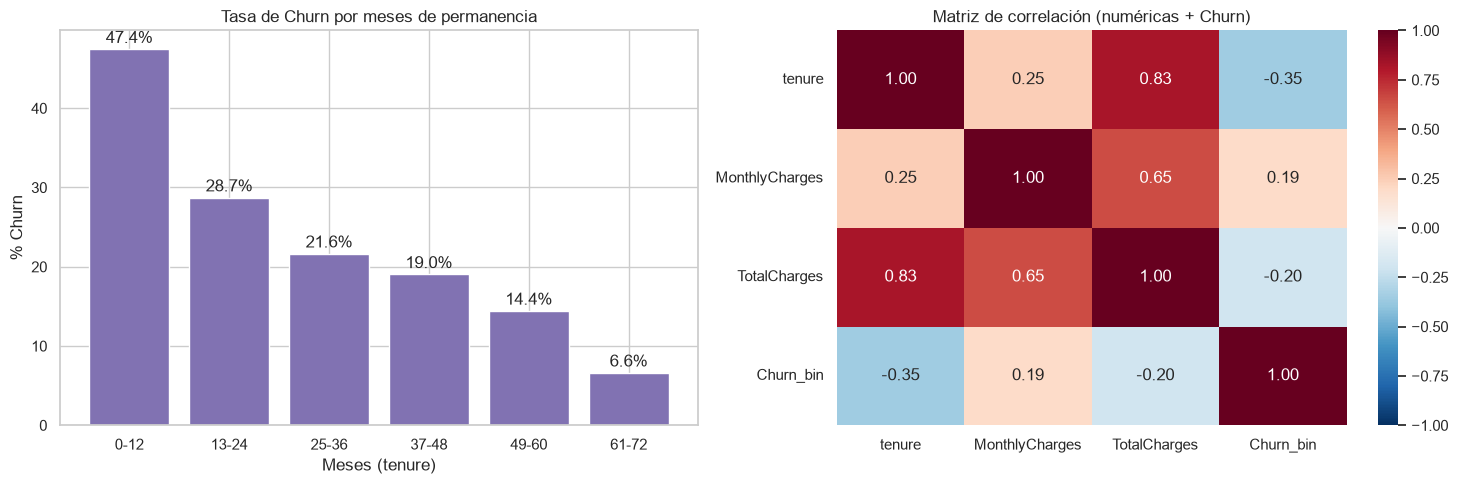

In [11]:
df_eda["tenure_grupo"] = pd.cut(df_eda["tenure"], bins=[-1, 12, 24, 36, 48, 60, 72],
                                labels=["0-12", "13-24", "25-36", "37-48", "49-60", "61-72"])
tasa_tenure = df_eda.groupby("tenure_grupo", observed=True)["Churn_bin"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(tasa_tenure.index.astype(str), tasa_tenure.values, color="#8172B2")
for i, v in enumerate(tasa_tenure.values):
    axes[0].text(i, v + 0.8, f"{v:.1f}%", ha="center")
axes[0].set_title("Tasa de Churn por meses de permanencia")
axes[0].set_xlabel("Meses (tenure)")
axes[0].set_ylabel("% Churn")

corr = df_eda[NUM_EDA + ["Churn_bin"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1], vmin=-1, vmax=1)
axes[1].set_title("Matriz de correlación (numéricas + Churn)")
plt.tight_layout()
plt.show()

### 4.7 Facturación asociada al churn en este dataset
Aquí se mide la **facturación mensual de los clientes que abandonaron**. No es una pérdida económica neta: el dataset no tiene costos, no dice cuántos meses más se habría quedado cada cliente ni si la empresa los reemplazó. La cifra anual es una **proyección con un supuesto explícito** (que esos clientes habrían pagado 12 meses más la misma factura).

In [12]:
facturacion_total = df_eda["MonthlyCharges"].sum()
facturacion_churn = df_eda.loc[df_eda["Churn"] == "Yes", "MonthlyCharges"].sum()
pct_clientes = df_eda["Churn_bin"].mean() * 100
pct_facturacion = facturacion_churn / facturacion_total * 100

print(f"Facturación mensual de todos los clientes          : {facturacion_total:,.2f} u.m.")
print(f"Facturación mensual de los clientes que abandonaron: {facturacion_churn:,.2f} u.m.")
print(f"Proyección a 12 meses (supuesto, no pérdida medida): {facturacion_churn * 12:,.2f} u.m.")
print(f"\nLos que abandonaron son el {pct_clientes:.1f}% de los clientes y el {pct_facturacion:.1f}% de la facturación mensual.")
print(f"Cargo mensual promedio -> abandonó: {df_eda.loc[df_eda.Churn == 'Yes', 'MonthlyCharges'].mean():.2f} u.m. | "
      f"continúa: {df_eda.loc[df_eda.Churn == 'No', 'MonthlyCharges'].mean():.2f} u.m.")

Facturación mensual de todos los clientes          : 456,116.60 u.m.
Facturación mensual de los clientes que abandonaron: 139,130.85 u.m.
Proyección a 12 meses (supuesto, no pérdida medida): 1,669,570.20 u.m.

Los que abandonaron son el 26.5% de los clientes y el 30.5% de la facturación mensual.
Cargo mensual promedio -> abandonó: 74.44 u.m. | continúa: 61.27 u.m.


### 4.8 Conclusiones del EDA
1. **Clases desbalanceadas:** 73,5 % *No* frente a 26,5 % *Yes*. Hay que balancear el entrenamiento y evaluar con métricas de la clase minoritaria.
2. **El tipo de contrato es la variable que más separa a los grupos:** los clientes *Month-to-month* abandonan un **42,7 %**, contra **2,8 %** de los que tienen contrato *Two year*.
3. **El primer año es crítico:** clientes con 0 a 12 meses abandonan un **47,4 %**, y quienes llevan más de 5 años un **6,6 %**. La mediana de permanencia es **10 meses** en los que abandonaron y **38 meses** en los que se quedaron. `tenure` es la numérica más correlacionada con churn (**-0,35**).
4. **Fibra óptica:** **41,9 %** de churn contra **7,4 %** en clientes sin internet. La fibra además es el servicio con el cargo mensual más alto (mediana de 91,7 u.m. contra 56,2 u.m. en DSL), así que su efecto puede mezclarse con el precio.
5. **Servicios de protección y soporte:** sin `OnlineSecurity` el churn es **41,8 %** y sin `TechSupport` **41,6 %**.
6. **Método de pago:** *Electronic check* tiene **45,3 %** de churn contra **15,2 %** con tarjeta de crédito automática.
7. **Facturación:** los que abandonaron pagaban **más al mes** (mediana de 79,65 u.m. contra 64,43 u.m.), pero acumulaban menos `TotalCharges` porque se fueron pronto.
8. **Perfil demográfico:** los adultos mayores abandonan más (**41,7 %** contra 23,6 %), igual que los clientes sin pareja y sin dependientes.
9. **Variables casi sin diferencia:** `gender` (0,8 puntos porcentuales) y `PhoneService` (1,8 puntos).
10. **Variables numéricas correlacionadas:** `TotalCharges` se parece mucho a `tenure * MonthlyCharges`, y la correlación entre `tenure` y `TotalCharges` es **0,83**. Esto complica la lectura de sus coeficientes en la Regresión Logística (sección 9.3).
11. **Facturación asociada:** quienes abandonaron son el 26,5 % de los clientes y el **30,5 % de la facturación mensual** (139.130,85 u.m. al mes).

Todas estas son **asociaciones** observadas en los datos. El EDA no permite afirmar que, por ejemplo, el cheque electrónico *cause* el abandono; puede estar relacionado con otros factores (como el tipo de cliente que elige ese medio de pago).

## 5. Preprocesamiento
### 5.1 Limpieza de datos
Decisiones:
- **`TotalCharges`**: se convierte a número. Las 11 cadenas vacías corresponden a clientes con `tenure = 0`, así que se imputan con **0** (todavía no han acumulado facturación). No se eliminan filas.
- **`customerID`**: se elimina porque es un identificador sin valor predictivo.
- **`SeniorCitizen`**: viene como 0/1; se pasa a `No`/`Yes` para tratarla igual que las demás variables binarias.
- **Categorías redundantes:** en los 6 servicios de internet aparece la categoría `No internet service`, y en `MultipleLines` aparece `No phone service`. Esa información ya está en `InternetService = No` y `PhoneService = No`. Si se dejan, el One-Hot Encoding crea columnas **idénticas** entre sí (colinealidad perfecta), y los coeficientes de la Regresión Logística dejan de ser interpretables. Por eso se recodifican a `No` ("no tiene el servicio"). No se pierde información.
- **`Churn`** (objetivo): se codifica como `Yes = 1` (**clase positiva**) y `No = 0`.
- **Duplicados**: al quitar `customerID` aparecen algunas filas idénticas, pero son clientes **distintos** con el mismo perfil (por ejemplo, clientes nuevos con el plan más básico), así que se conservan.

In [13]:
SERVICIOS_INTERNET = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                      "TechSupport", "StreamingTV", "StreamingMovies"]

# Comprobación de la redundancia antes de recodificar
for col in SERVICIOS_INTERNET:
    iguales = (df_raw[col] == "No internet service").equals(df_raw["InternetService"] == "No")
    print(f"'{col} = No internet service' coincide con 'InternetService = No': {iguales}")
print("'MultipleLines = No phone service' coincide con 'PhoneService = No':",
      (df_raw["MultipleLines"] == "No phone service").equals(df_raw["PhoneService"] == "No"))

'OnlineSecurity = No internet service' coincide con 'InternetService = No': True
'OnlineBackup = No internet service' coincide con 'InternetService = No': True
'DeviceProtection = No internet service' coincide con 'InternetService = No': True
'TechSupport = No internet service' coincide con 'InternetService = No': True
'StreamingTV = No internet service' coincide con 'InternetService = No': True
'StreamingMovies = No internet service' coincide con 'InternetService = No': True
'MultipleLines = No phone service' coincide con 'PhoneService = No': True


In [14]:
df = df_raw.copy()

# TotalCharges: texto -> número; las cadenas vacías (tenure = 0) se imputan con 0
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
assert (df.loc[df["TotalCharges"].isna(), "tenure"] == 0).all()
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)

df = df.drop(columns="customerID")
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# Categorías redundantes -> "No" (no tiene el servicio)
for col in SERVICIOS_INTERNET:
    df[col] = df[col].replace("No internet service", "No")
df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print("Nulos después de limpiar:", int(df.isnull().sum().sum()))
print("Filas con perfil idéntico (se conservan):", df.duplicated().sum())
print("Categorías de OnlineSecurity:", sorted(df["OnlineSecurity"].unique()))
print("Shape final:", df.shape)

Nulos después de limpiar: 0
Filas con perfil idéntico (se conservan): 22
Categorías de OnlineSecurity: ['No', 'Yes']
Shape final: (7043, 20)


### 5.2 Separación de variables predictoras (X) y objetivo (y)

In [15]:
NUM_COLS = ["tenure", "MonthlyCharges", "TotalCharges"]
CAT_COLS = [c for c in df.columns if c not in NUM_COLS + ["Churn"]]

X = df[NUM_COLS + CAT_COLS]
y = df["Churn"]
print(f"{len(NUM_COLS)} numéricas : {NUM_COLS}")
print(f"{len(CAT_COLS)} categóricas: {CAT_COLS}")
print("Objetivo y: 1 = Churn Yes (clase positiva), 0 = Churn No")

3 numéricas : ['tenure', 'MonthlyCharges', 'TotalCharges']
16 categóricas: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Objetivo y: 1 = Churn Yes (clase positiva), 0 = Churn No


### 5.3 División entrenamiento / prueba (80 / 20, estratificada)
`stratify=y` mantiene la misma proporción de churn (26,5 %) en ambos conjuntos. El conjunto de prueba **no se usa** para ajustar nada: ni el escalador, ni el codificador, ni el balanceo. Solo se usa en la evaluación final.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Entrenamiento: {X_train.shape[0]} filas | churn = {y_train.mean()*100:.2f}%")
print(f"Prueba       : {X_test.shape[0]} filas | churn = {y_test.mean()*100:.2f}%")

Entrenamiento: 5634 filas | churn = 26.54%
Prueba       : 1409 filas | churn = 26.54%


### 5.4 Escalamiento de numéricas y codificación de categóricas
Se definen dos transformadores, que luego van dentro del pipeline de cada modelo:
- **`escalador`**: aplica `StandardScaler` a las 3 numéricas (media 0, desviación 1) y deja pasar las categóricas sin cambios. Es indispensable para KNN y SVM, que trabajan con distancias, y ayuda a la Regresión Logística.
- **`codificador`**: aplica `OneHotEncoder(drop="first")` a las categóricas. Con `drop="first"` se elimina la primera categoría (en orden alfabético) de cada variable, que queda como **categoría de referencia**. Así, cada coeficiente de la Regresión Logística se interpreta como el cambio frente a esa referencia (por ejemplo, `Contract = Two year` frente a `Contract = Month-to-month`). Con `handle_unknown="ignore"`, una categoría nunca vista no rompe la predicción: se codifica como la referencia.

Ambos se ajustan **solo con datos de entrenamiento** (dentro del pipeline), para evitar fuga de información (*data leakage*).

In [17]:
escalador = ColumnTransformer(
    [("num", StandardScaler(), NUM_COLS)],
    remainder="passthrough", verbose_feature_names_out=False,
).set_output(transform="pandas")

codificador = ColumnTransformer(
    [("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CAT_COLS)],
    remainder="passthrough", verbose_feature_names_out=False,
)

# Solo para mostrar el resultado; en los modelos esto ocurre dentro del pipeline
X_train_esc = escalador.fit_transform(X_train)
X_train_prep = codificador.fit_transform(X_train_esc)
nombres_features = codificador.get_feature_names_out()
print("Variables originales:", X_train.shape[1], "-> variables después de codificar:", X_train_prep.shape[1])

categorias = codificador.named_transformers_["cat"].categories_
pd.DataFrame({"Variable": CAT_COLS,
              "Categoría de referencia (eliminada)": [c[0] for c in categorias],
              "Otras categorías": [", ".join(map(str, c[1:])) for c in categorias]})

Variables originales: 19 -> variables después de codificar: 23


,Variable,Categoría de referencia (eliminada),Otras categorías
0,gender,Female,Male
1,SeniorCitizen,No,Yes
2,Partner,No,Yes
3,Dependents,No,Yes
4,PhoneService,No,Yes
5,MultipleLines,No,Yes
6,InternetService,DSL,"Fiber optic, No"
7,OnlineSecurity,No,Yes
8,OnlineBackup,No,Yes
9,DeviceProtection,No,Yes


### 5.5 Balanceo de clases con SMOTENC
**SMOTE** crea ejemplos sintéticos de la clase minoritaria (`Churn = 1`) interpolando entre un cliente real y uno de sus vecinos cercanos. El problema es que, si se aplica **después** del One-Hot Encoding, también interpola las columnas binarias y genera valores como 0,37 en una columna que solo debería valer 0 o 1 (un cliente "37 % con fibra óptica"), lo cual no tiene sentido.

**SMOTENC** (SMOTE para variables Nominales y Continuas) resuelve eso: interpola solo las numéricas y, para cada categórica, asigna la categoría más frecuente entre los vecinos. Por eso se aplica **entre** el escalador (para que las distancias usen numéricas en la misma escala) y el codificador.

Reglas que se respetan:
- Se aplica **solo al conjunto de entrenamiento**. El de prueba conserva la distribución real (26,5 % de churn); si no, las métricas serían optimistas.
- Va **dentro de un pipeline** de `imblearn`, así que en la validación cruzada solo se balancea la parte de entrenamiento de cada fold, nunca la parte de validación.

La siguiente celda compara ambas técnicas sobre el conjunto de entrenamiento.

SMOTE tras One-Hot: 2067 de 2644 filas sintéticas tienen valores fraccionarios en columnas binarias


SMOTENC: todas las categorías generadas son categorías reales: True

         Antes de SMOTENC  Después de SMOTENC
No (0)               4139                4139
Yes (1)              1495                4139


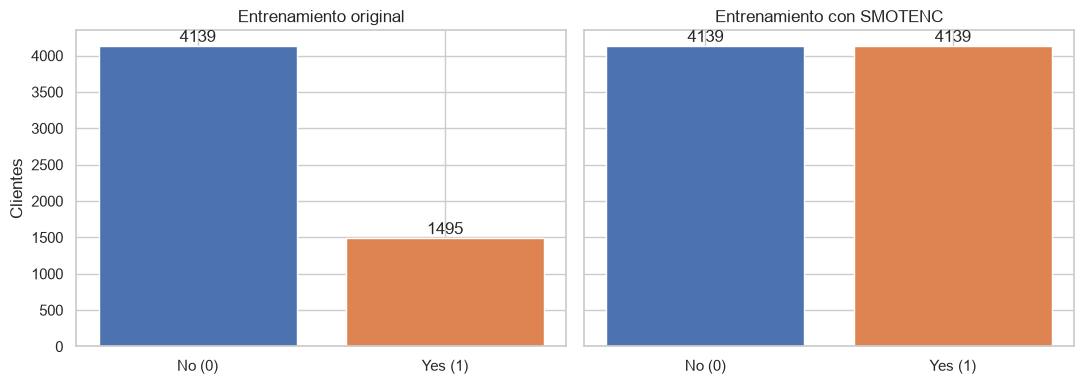

In [18]:
n_dummies = len(codificador.named_transformers_["cat"].get_feature_names_out())

# SMOTE después del One-Hot: revisa si aparecen valores entre 0 y 1 en columnas binarias
X_smote, y_smote = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train_prep, y_train)
sinteticos = X_smote[len(X_train_prep):, :n_dummies]
fraccionarios = ((sinteticos > 0) & (sinteticos < 1)).any(axis=1).sum()
print(f"SMOTE tras One-Hot: {fraccionarios} de {len(sinteticos)} filas sintéticas tienen valores fraccionarios en columnas binarias")

# SMOTENC sobre los datos escalados (categóricas todavía como texto)
X_nc, y_nc = SMOTENC(categorical_features=CAT_COLS, random_state=RANDOM_STATE).fit_resample(X_train_esc, y_train)
validas = all(set(X_nc[c]) <= set(X_train_esc[c]) for c in CAT_COLS)
print(f"SMOTENC: todas las categorías generadas son categorías reales: {validas}")

antes = y_train.value_counts().sort_index()
despues = pd.Series(y_nc).value_counts().sort_index()
print()
print(pd.DataFrame({"Antes de SMOTENC": antes.values, "Después de SMOTENC": despues.values},
                   index=["No (0)", "Yes (1)"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, datos, titulo in [(axes[0], antes, "Entrenamiento original"), (axes[1], despues, "Entrenamiento con SMOTENC")]:
    ax.bar(["No (0)", "Yes (1)"], datos.values, color=colores)
    for i, v in enumerate(datos.values):
        ax.text(i, v + 50, str(v), ha="center")
    ax.set_title(titulo)
axes[0].set_ylabel("Clientes")
plt.tight_layout()
plt.show()

### 5.6 ¿Importa la técnica de balanceo? Comparación con la Regresión Logística
Para no elegir SMOTENC "por ser más sofisticado", se comparan 4 estrategias con validación cruzada de 10 folds sobre el entrenamiento, usando el mismo modelo (Regresión Logística):
1. Sin balanceo.
2. `class_weight="balanced"`: no crea datos; le da más peso a los errores en la clase minoritaria.
3. SMOTE después del One-Hot (la versión que tenía valores fraccionarios).
4. SMOTENC.

El Brier score mide qué tan buenas son las probabilidades (más bajo es mejor). `cross_validate` lo devuelve con signo negativo, por eso se invierte.

In [19]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
METRICAS_BAL = {"F1": "f1", "Recall": "recall", "Precision": "precision",
                "ROC-AUC": "roc_auc", "Brier": "neg_brier_score"}


def lr():
    return LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)


estrategias = {
    "Sin balanceo": SkPipeline([("escalar", clone(escalador)), ("codificar", clone(codificador)), ("modelo", lr())]),
    "class_weight='balanced'": SkPipeline([("escalar", clone(escalador)), ("codificar", clone(codificador)),
                                           ("modelo", lr().set_params(class_weight="balanced"))]),
    "SMOTE tras One-Hot": ImbPipeline([("escalar", clone(escalador)), ("codificar", clone(codificador)),
                                       ("smote", SMOTE(random_state=RANDOM_STATE)), ("modelo", lr())]),
    "SMOTENC": ImbPipeline([("escalar", clone(escalador)),
                            ("smotenc", SMOTENC(categorical_features=CAT_COLS, random_state=RANDOM_STATE)),
                            ("codificar", clone(codificador)), ("modelo", lr())]),
}

filas = []
for nombre, pipe in estrategias.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=METRICAS_BAL, n_jobs=-1)
    fila = {"Estrategia": nombre}
    fila.update({m: abs(r[f"test_{m}"].mean()) for m in METRICAS_BAL})
    filas.append(fila)
pd.DataFrame(filas).set_index("Estrategia").round(4)

,F1,Recall,Precision,ROC-AUC,Brier
Estrategia,,,,,
Sin balanceo,0.5926,0.5426,0.6549,0.8459,0.1351
class_weight='balanced',0.6313,0.8034,0.5203,0.8456,0.1651
SMOTE tras One-Hot,0.6322,0.7947,0.5252,0.8460,0.1630
SMOTENC,0.6312,0.7800,0.5306,0.8422,0.1606


**Lectura de la tabla:**
- **Sin balanceo**, el modelo tiene la mejor Precision y el mejor Brier, pero su Recall cae a 0,54: deja escapar casi la mitad de los clientes que abandonan. Para retención eso es un problema.
- Las **tres estrategias de balanceo** rinden prácticamente igual (F1 entre 0,631 y 0,632, ROC-AUC entre 0,842 y 0,846). Es decir, **la conclusión del trabajo no depende de qué técnica de balanceo se elija**.
- Se usa **SMOTENC** para los 5 modelos porque: (a) respeta el tipo de cada variable, sin crear categorías imposibles; y (b) funciona con todos los modelos. `class_weight` sería igual de válido para la Regresión Logística, pero KNN y Naive Bayes no tienen ese parámetro, y se quiere tratar a los 5 modelos con la misma estrategia.
- Balancear empeora el Brier score: las probabilidades quedan **sobreestimadas** porque el modelo aprendió con 50 % de churn en vez del 26,5 % real. Eso se corrige con calibración en la sección 9.4.

## 6. Entrenamiento y evaluación de modelos
Cada modelo se entrena dentro del mismo pipeline: **escalar, luego SMOTENC (solo al entrenar), luego codificar y luego el clasificador**. Así todos reciben exactamente los mismos datos y la comparación es justa. Al predecir, el pipeline salta SMOTENC automáticamente.

| Modelo | Configuración |
|---|---|
| Logistic Regression | `max_iter=1000` (regularización L2 por defecto, `C=1`) |
| KNN | `n_neighbors=5` (distancia euclidiana) |
| SVM | kernel `rbf`, `probability=True` (para obtener probabilidades y ROC-AUC) |
| Decision Tree | parámetros por defecto (sin límite de profundidad) |
| Naive Bayes | `GaussianNB` |

Se usan los hiperparámetros por defecto en los 5 modelos, sin ajustarlos. Es una comparación en igualdad de condiciones, pero significa que algunos modelos (en especial KNN y Decision Tree) podrían mejorar con ajuste de hiperparámetros.

**Todas las métricas se calculan para la clase positiva `Churn = Yes` (`pos_label=1`)**, que es la que interesa detectar.

In [20]:
modelos = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Naive Bayes": GaussianNB(),
}


def crear_pipeline(modelo):
    # escalar -> balancear (solo en fit) -> codificar -> clasificador
    return ImbPipeline([
        ("escalar", clone(escalador)),
        ("smotenc", SMOTENC(categorical_features=CAT_COLS, random_state=RANDOM_STATE)),
        ("codificar", clone(codificador)),
        ("modelo", clone(modelo)),
    ])


def calcular_metricas(y_real, y_pred, y_proba):
    # Métricas de la clase positiva Churn = Yes (1)
    return {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(y_real, y_pred, pos_label=1),
        "Recall": recall_score(y_real, y_pred, pos_label=1),
        "F1-Score": f1_score(y_real, y_pred, pos_label=1),
        "ROC-AUC": roc_auc_score(y_real, y_proba),
    }

In [21]:
pipelines, resultados, resultados_train, probas, preds = {}, [], [], {}, {}

for nombre, modelo in modelos.items():
    pipe = crear_pipeline(modelo)
    pipe.fit(X_train, y_train)
    pipelines[nombre] = pipe

    # Prueba
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    preds[nombre], probas[nombre] = y_pred, y_proba
    resultados.append({"Modelo": nombre, **calcular_metricas(y_test, y_pred, y_proba)})

    # Entrenamiento (para medir overfitting)
    resultados_train.append({"Modelo": nombre, **calcular_metricas(
        y_train, pipe.predict(X_train), pipe.predict_proba(X_train)[:, 1])})

    print("=" * 62)
    print(f"  {nombre.upper()}")
    print("=" * 62)
    print(classification_report(y_test, y_pred, target_names=["No Churn (0)", "Churn (1)"], digits=4))
    print(f"ROC-AUC: {resultados[-1]['ROC-AUC']:.4f}\n")

  LOGISTIC REGRESSION
              precision    recall  f1-score   support

No Churn (0)     0.8955    0.7285    0.8034      1035
   Churn (1)     0.5044    0.7647    0.6079       374

    accuracy                         0.7381      1409
   macro avg     0.6999    0.7466    0.7056      1409
weighted avg     0.7917    0.7381    0.7515      1409

ROC-AUC: 0.8327



  KNN
              precision    recall  f1-score   support

No Churn (0)     0.8751    0.7179    0.7887      1035
   Churn (1)     0.4786    0.7166    0.5739       374

    accuracy                         0.7175      1409
   macro avg     0.6769    0.7172    0.6813      1409
weighted avg     0.7699    0.7175    0.7317      1409

ROC-AUC: 0.7757



  SVM
              precision    recall  f1-score   support

No Churn (0)     0.8822    0.7671    0.8207      1035
   Churn (1)     0.5265    0.7166    0.6070       374

    accuracy                         0.7537      1409
   macro avg     0.7044    0.7419    0.7138      1409
weighted avg     0.7878    0.7537    0.7640      1409

ROC-AUC: 0.8185



  DECISION TREE
              precision    recall  f1-score   support

No Churn (0)     0.8383    0.7614    0.7980      1035
   Churn (1)     0.4733    0.5936    0.5267       374

    accuracy                         0.7168      1409
   macro avg     0.6558    0.6775    0.6623      1409
weighted avg     0.7414    0.7168    0.7260      1409

ROC-AUC: 0.6783



  NAIVE BAYES
              precision    recall  f1-score   support

No Churn (0)     0.8918    0.7324    0.8042      1035
   Churn (1)     0.5045    0.7540    0.6045       374

    accuracy                         0.7381      1409
   macro avg     0.6981    0.7432    0.7044      1409
weighted avg     0.7890    0.7381    0.7512      1409

ROC-AUC: 0.8198



### 6.1 Tabla comparativa de métricas (conjunto de prueba)
En verde, el mejor valor de cada métrica.

> **Nota de reproducibilidad:** las salidas guardadas se generaron con el entorno de Colab (Python 3.13, scikit-learn 1.6.1, imbalanced-learn 0.14.2). Al re-ejecutar en otra versión o plataforma, algunas métricas de prueba pueden variar en el tercer decimal y los conteos de la matriz de confusión en unos pocos clientes, por desempates en KNN y en SMOTENC. Las conclusiones no cambian.

In [22]:
tabla = pd.DataFrame(resultados).set_index("Modelo")
tabla.style.format("{:.4f}").highlight_max(axis=0, color="#b6e3b6")

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Modelo,,,,,
Logistic Regression,0.7381,0.5044,0.7647,0.6079,0.8327
KNN,0.7175,0.4786,0.7166,0.5739,0.7757
SVM,0.7537,0.5265,0.7166,0.6070,0.8185
Decision Tree,0.7168,0.4733,0.5936,0.5267,0.6783
Naive Bayes,0.7381,0.5045,0.7540,0.6045,0.8198


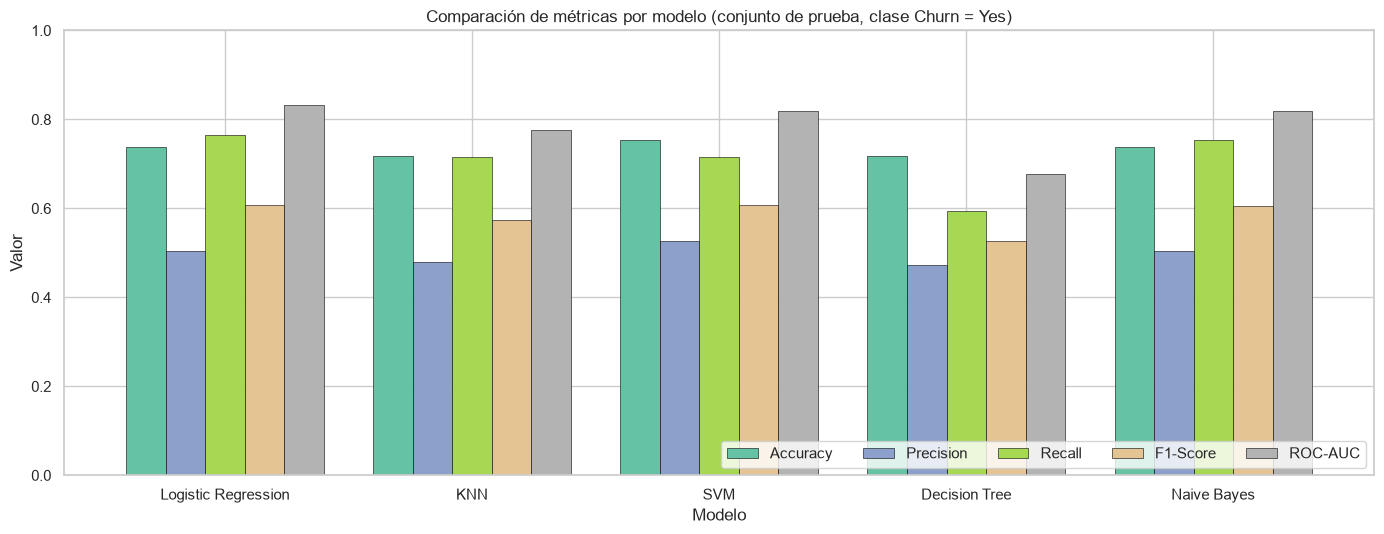

In [23]:
ax = tabla.plot(kind="bar", figsize=(14, 5.5), width=0.8, colormap="Set2", edgecolor="black", linewidth=0.4)
ax.set_title("Comparación de métricas por modelo (conjunto de prueba, clase Churn = Yes)")
ax.set_ylabel("Valor")
ax.set_ylim(0, 1)
ax.set_xticklabels(tabla.index, rotation=0)
ax.legend(loc="lower right", ncol=5)
plt.tight_layout()
plt.show()

### 6.2 Matrices de confusión
- **TN**: no abandona y el modelo dijo que no. **FP**: no abandona, pero el modelo dijo que sí (falsa alarma).
- **FN**: abandona, pero el modelo dijo que no (**cliente perdido sin aviso**). **TP**: abandona y el modelo lo detectó.

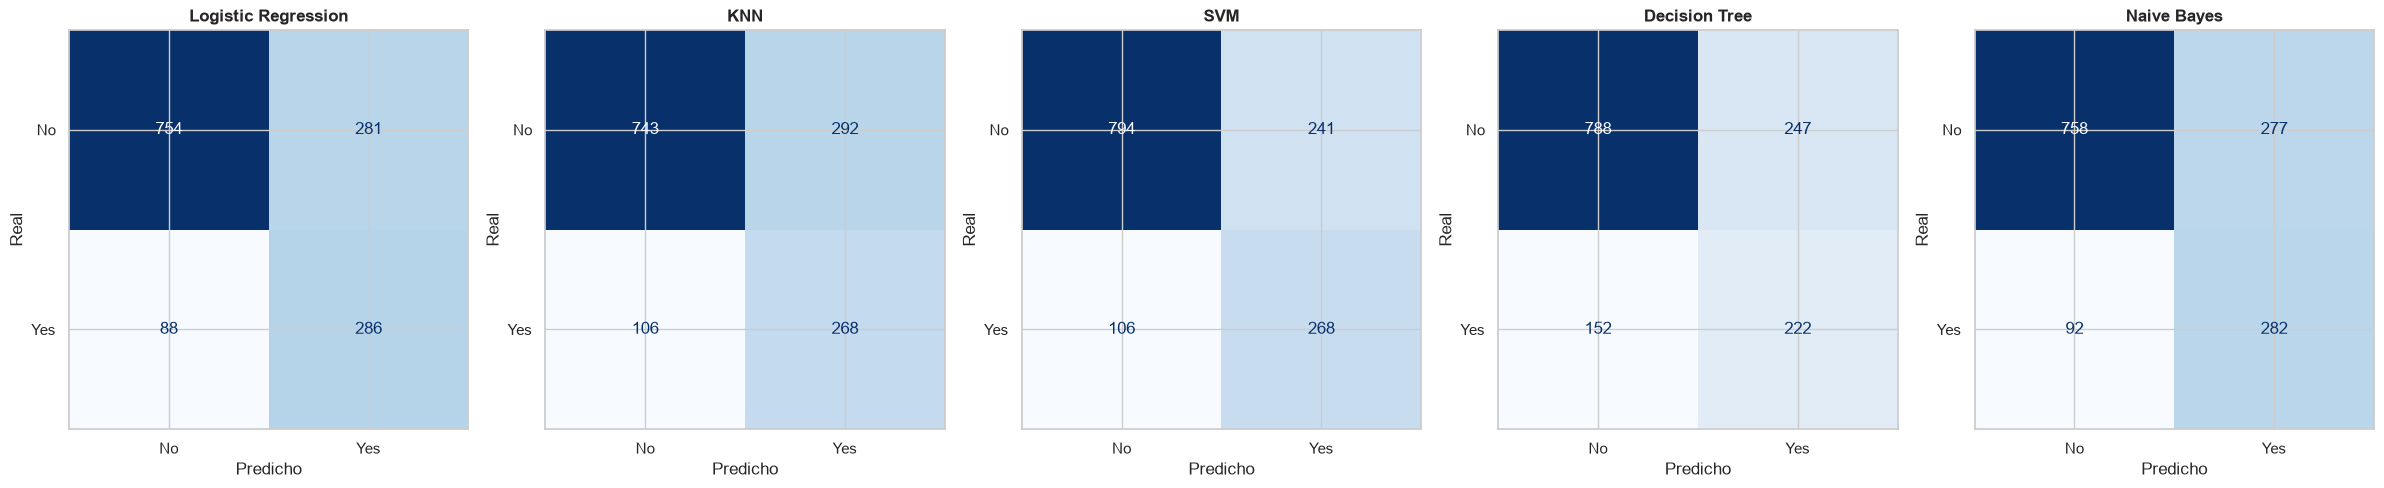

,TN,FP (falsa alarma),FN (churn no detectado),TP (churn detectado)
Modelo,,,,
Logistic Regression,754,281,88,286
KNN,743,292,106,268
SVM,794,241,106,268
Decision Tree,788,247,152,222
Naive Bayes,758,277,92,282


In [24]:
fig, axes = plt.subplots(1, 5, figsize=(24, 4.8))
for ax, (nombre, y_pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["No", "Yes"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(nombre, fontweight="bold")
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

filas = []
for nombre, y_pred in preds.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    filas.append({"Modelo": nombre, "TN": tn, "FP (falsa alarma)": fp, "FN (churn no detectado)": fn, "TP (churn detectado)": tp})
pd.DataFrame(filas).set_index("Modelo")

### 6.3 Curvas ROC

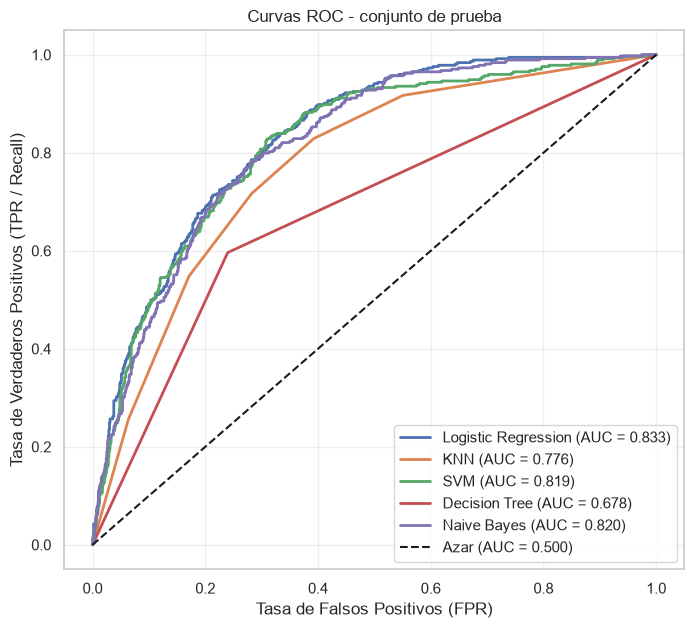

In [25]:
plt.figure(figsize=(8, 7))
for nombre, y_proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {roc_auc_score(y_test, y_proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.500)")
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR / Recall)")
plt.title("Curvas ROC - conjunto de prueba")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

### 6.4 Diagnóstico de overfitting (entrenamiento vs. prueba)
Si un modelo rinde mucho mejor en entrenamiento que en prueba, **memorizó** los datos en vez de aprender patrones generales. Las métricas de entrenamiento se calculan sobre los datos reales de entrenamiento (sin los sintéticos de SMOTENC).

In [26]:
tabla_train = pd.DataFrame(resultados_train).set_index("Modelo")
overfit = pd.DataFrame({
    "F1 train": tabla_train["F1-Score"], "F1 test": tabla["F1-Score"],
    "Brecha F1": tabla_train["F1-Score"] - tabla["F1-Score"],
    "AUC train": tabla_train["ROC-AUC"], "AUC test": tabla["ROC-AUC"],
    "Brecha AUC": tabla_train["ROC-AUC"] - tabla["ROC-AUC"],
})
arbol = pipelines["Decision Tree"].named_steps["modelo"]
print(f"Decision Tree sin podar -> profundidad: {arbol.get_depth()} | hojas: {arbol.get_n_leaves()}")
overfit.style.format("{:.4f}").background_gradient(subset=["Brecha F1", "Brecha AUC"], cmap="Reds")

Decision Tree sin podar -> profundidad: 29 | hojas: 1433


,F1 train,F1 test,Brecha F1,AUC train,AUC test,Brecha AUC
Modelo,,,,,,
Logistic Regression,0.6314,0.6079,0.0235,0.8447,0.8327,0.0121
KNN,0.7130,0.5739,0.1391,0.9278,0.7757,0.1521
SVM,0.6650,0.6070,0.0580,0.8710,0.8185,0.0524
Decision Tree,0.9963,0.5267,0.4696,1.0000,0.6783,0.3217
Naive Bayes,0.6143,0.6045,0.0098,0.8307,0.8198,0.0109


## 7. Fortalezas y debilidades de cada modelo (según los resultados)
Resultados en prueba; entre paréntesis, la media de la validación cruzada de 10 folds (sección 8).

#### Logistic Regression - F1 0,61 (0,631), ROC-AUC 0,833 (0,842), Recall 0,765

**Fortalezas**
- Tiene el **mejor F1, el mejor ROC-AUC y el mejor Recall promedio** en la validación cruzada.
- Detecta **286 de 374** clientes que abandonan (88 falsos negativos).
- **Casi no sobreajusta:** brecha entre entrenamiento y prueba de 0,02 en F1 y 0,01 en AUC.
- Es rápida, liviana e **interpretable** (coeficientes y odds ratios, sección 9.3).

**Debilidades**
- **Precision de aprox. 0,50:** unas 281 falsas alarmas, es decir, 1 de cada 2 alertas corresponde a un cliente que no se iba.
- Su frontera de decisión es lineal: no capta interacciones entre variables si no se crean a mano.
- Es sensible a variables correlacionadas (`tenure` y `TotalCharges`), lo que complica leer algunos coeficientes por separado.

#### KNN - F1 0,57 (0,568), ROC-AUC 0,78 (0,775), Recall 0,72

**Fortalezas**
- Es simple, no supone ninguna forma de los datos y puede captar relaciones locales no lineales.

**Debilidades**
- **Sobreajuste notable:** AUC de 0,93 en entrenamiento contra 0,78 en prueba (brecha de aprox. 0,15). Con k = 5 cada predicción depende de muy pocos vecinos.
- Su Precision está entre las más bajas (aprox. 0,48).
- Con 23 columnas, la mayoría binarias, las distancias euclidianas pierden capacidad de distinguir clientes.
- Es lento al predecir (calcula la distancia a todo el entrenamiento) y no es interpretable.

#### SVM (RBF) - F1 0,607 (0,623), ROC-AUC 0,819 (0,824), Recall 0,717

**Fortalezas**
- Tiene el **mayor Accuracy (0,754)** y la **mayor Precision (0,527)**: es el que menos falsas alarmas genera (241).
- En F1 **no tiene una diferencia estadísticamente significativa con la Regresión Logística** (sección 8.6).

**Debilidades**
- Detecta menos clientes que abandonan: Recall de 0,717, con **106 falsos negativos** (18 más que la Regresión Logística).
- Es una caja negra: el kernel RBF no permite explicar por qué un cliente es riesgoso.
- Es el más costoso de entrenar y muestra un sobreajuste moderado (brecha de AUC de 0,05).

#### Decision Tree (sin podar) - F1 0,527 (0,523), ROC-AUC 0,678 (0,675), Recall 0,594

**Fortalezas**
- No necesita escalamiento, capta relaciones no lineales y, si se poda, genera reglas fáciles de explicar.

**Debilidades**
- **Peor modelo en F1, Recall y ROC-AUC.** No detecta **152 de 374** clientes que abandonan (41 %).
- **Sobreajuste extremo:** F1 de 0,996 y AUC de 1,000 en entrenamiento, contra 0,527 y 0,678 en prueba. El árbol creció hasta **29 niveles y 1.433 hojas**: memorizó a cada cliente.
- Sus hojas puras dan probabilidades de casi 0 o 1, por lo que ordena mal a los clientes (AUC bajo).

#### Naive Bayes (Gaussiano) - F1 0,60 (0,615), ROC-AUC 0,82 (0,830), Recall 0,75

**Fortalezas**
- Resultados cercanos a la Regresión Logística: Recall de aprox. 0,75 y ROC-AUC de 0,82 en prueba.
- Casi no sobreajusta (brechas de 0,01) y es el más rápido de entrenar.

**Debilidades**
- Supone que las variables son **independientes** y **normales** dentro de cada clase, algo que no se cumple aquí (`tenure` y `TotalCharges` están correlacionadas y las columnas One-Hot son binarias). Funciona razonablemente a pesar de eso, pero sus probabilidades individuales son poco confiables.
- Es menos interpretable que la Regresión Logística para explicar un caso individual.

## 8. Validación estadística: ANOVA, Friedman y comparaciones por pares
Un solo conjunto de prueba da **un único número por modelo**, y con eso no se puede saber si las diferencias son reales o fruto del azar de la partición. Para tener **varias mediciones por modelo** se usa **validación cruzada estratificada de 10 folds** sobre el conjunto de entrenamiento (SMOTENC dentro de cada fold). Resultado: 10 valores de cada métrica por modelo.

Los 5 modelos se evalúan sobre **los mismos 10 folds**, así que sus resultados están **emparejados** por fold. Esto es importante para elegir la prueba estadística (sección 8.3).

> Para la SVM en la validación cruzada se usa `probability=False`: el ROC-AUC se calcula con `decision_function`, que ordena a los clientes igual y evita entrenar 5 modelos internos extra por fold.

In [27]:
METRICAS = {"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall",
            "F1-Score": "f1", "ROC-AUC": "roc_auc"}

scores_cv = {}
for nombre, modelo in modelos.items():
    if nombre == "SVM":
        modelo = clone(modelo).set_params(probability=False)
    r = cross_validate(crear_pipeline(modelo), X_train, y_train, cv=cv, scoring=METRICAS, n_jobs=-1)
    scores_cv[nombre] = {m: r[f"test_{m}"] for m in METRICAS}
    print(f"{nombre:<20} F1 = {scores_cv[nombre]['F1-Score'].mean():.4f} +/- {scores_cv[nombre]['F1-Score'].std():.4f}"
          f" | ROC-AUC = {scores_cv[nombre]['ROC-AUC'].mean():.4f} +/- {scores_cv[nombre]['ROC-AUC'].std():.4f}")

Logistic Regression  F1 = 0.6312 +/- 0.0262 | ROC-AUC = 0.8422 +/- 0.0164


KNN                  F1 = 0.5680 +/- 0.0271 | ROC-AUC = 0.7746 +/- 0.0146


SVM                  F1 = 0.6234 +/- 0.0198 | ROC-AUC = 0.8240 +/- 0.0176


Decision Tree        F1 = 0.5230 +/- 0.0433 | ROC-AUC = 0.6752 +/- 0.0327


Naive Bayes          F1 = 0.6152 +/- 0.0243 | ROC-AUC = 0.8304 +/- 0.0132


In [28]:
# Resumen: media +/- desviación estándar de los 10 folds
resumen_cv = pd.DataFrame({n: {m: f"{v.mean():.4f} +/- {v.std():.4f}" for m, v in s.items()}
                           for n, s in scores_cv.items()}).T
resumen_cv

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.7581 +/- 0.0190,0.5306 +/- 0.0253,0.7800 +/- 0.0350,0.6312 +/- 0.0262,0.8422 +/- 0.0164
KNN,0.7173 +/- 0.0154,0.4777 +/- 0.0198,0.7018 +/- 0.0506,0.5680 +/- 0.0271,0.7746 +/- 0.0146
SVM,0.7687 +/- 0.0132,0.5495 +/- 0.0197,0.7218 +/- 0.0367,0.6234 +/- 0.0198,0.8240 +/- 0.0176
Decision Tree,0.7226 +/- 0.0250,0.4814 +/- 0.0399,0.5739 +/- 0.0546,0.5230 +/- 0.0433,0.6752 +/- 0.0327
Naive Bayes,0.7462 +/- 0.0187,0.5155 +/- 0.0248,0.7646 +/- 0.0400,0.6152 +/- 0.0243,0.8304 +/- 0.0132


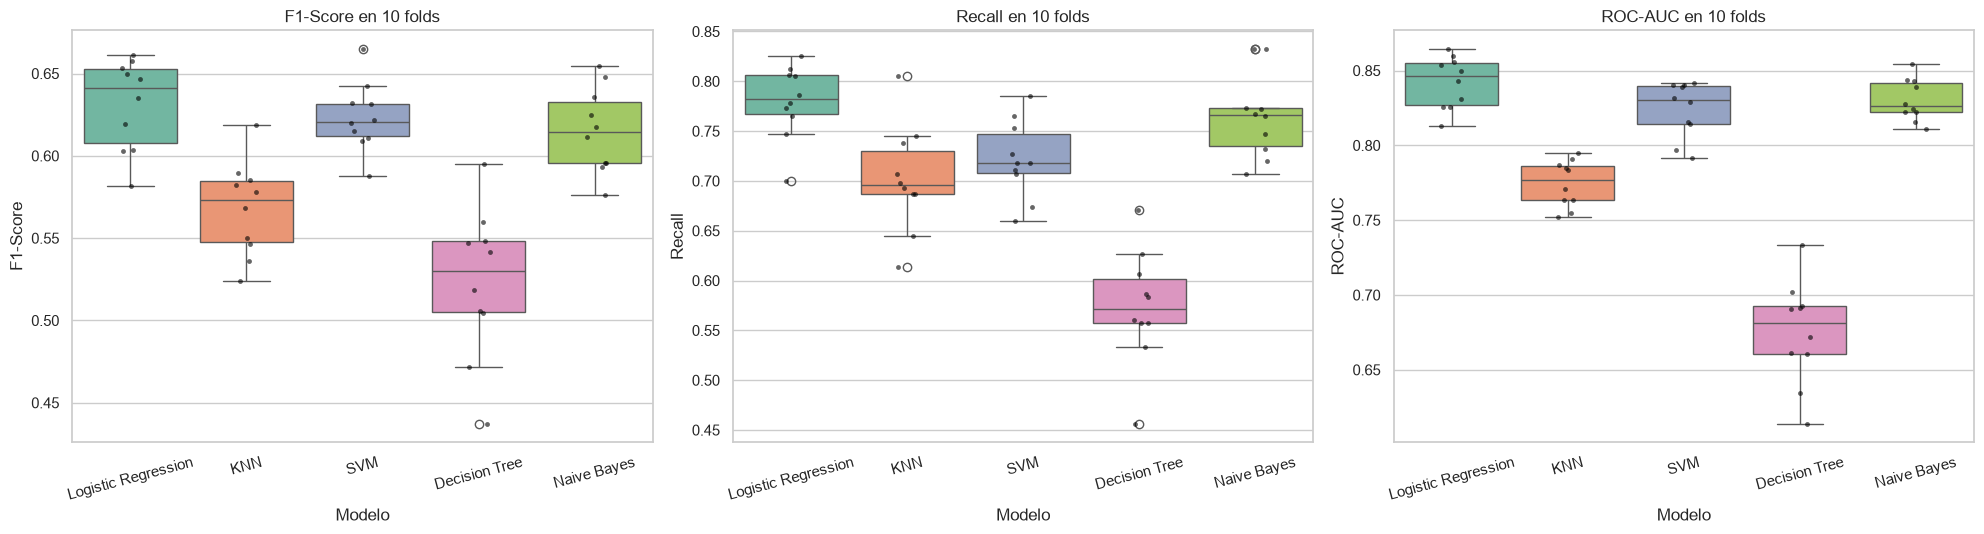

In [29]:
# Formato largo: una fila por (modelo, fold)
cv_largo = pd.DataFrame([{"Modelo": n, "Fold": i + 1, **{m: s[m][i] for m in METRICAS}}
                         for n, s in scores_cv.items() for i in range(10)])

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, m in zip(axes, ["F1-Score", "Recall", "ROC-AUC"]):
    sns.boxplot(data=cv_largo, x="Modelo", y=m, ax=ax, palette="Set2")
    sns.stripplot(data=cv_largo, x="Modelo", y=m, ax=ax, color="black", size=3.5, alpha=0.6)
    ax.set_title(f"{m} en 10 folds")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

### 8.1 Hipótesis
**Hipótesis: existe un mejor modelo basado en diferencias significativas entre métricas**
- **H₀:** no existen diferencias entre los modelos comparados (las 5 medias, o en Friedman las 5 distribuciones, de la métrica son iguales).
- **H₁:** al menos un modelo presenta diferencias respecto a los demás.

Nivel de significancia: **alfa = 0,05**. Si el *p-value* es menor que 0,05, se rechaza H₀. Rechazar H₀ indica que **al menos un** modelo es distinto; no dice cuál es el mejor. Para eso se hacen comparaciones por pares (sección 8.6). Y si no se rechaza H₀, eso **no demuestra** que los modelos sean iguales: solo indica que los datos no alcanzan para detectar una diferencia.

Se analizan principalmente 3 métricas: **F1-Score** (equilibrio entre Precision y Recall), **ROC-AUC** (capacidad de ordenar a los clientes por riesgo) y **Recall** (clientes que abandonan y se detectan).

### 8.2 ANOVA de un factor (análisis exploratorio, como pide el enunciado)
El ANOVA compara las medias de los 5 modelos y supone:
1. **Independencia** de las observaciones.
2. **Normalidad** dentro de cada grupo (se revisa con Shapiro-Wilk).
3. **Homogeneidad de varianzas** (se revisa con Levene).

In [30]:
filas = []
for m in METRICAS:
    grupos = [scores_cv[n][m] for n in modelos]
    F, p = f_oneway(*grupos)
    filas.append({"Métrica": m, "F": round(F, 4), "p-value": p,
                  "Shapiro: grupos con p > 0,05": f"{sum(shapiro(g).pvalue > 0.05 for g in grupos)}/5",
                  "Levene p-value": round(levene(*grupos).pvalue, 4),
                  "Decisión (alfa = 0,05)": "Se rechaza H0" if p < 0.05 else "No se rechaza H0"})
anova = pd.DataFrame(filas).set_index("Métrica")
anova.style.format({"p-value": "{:.2e}", "F": "{:.4f}"})

,F,p-value,"Shapiro: grupos con p > 0,05",Levene p-value,"Decisión (alfa = 0,05)"
Métrica,,,,,
Accuracy,12.7553,5.09e-07,5/5,0.284200,Se rechaza H0
Precision,11.9824,1.03e-06,5/5,0.100200,Se rechaza H0
Recall,30.7988,2.29e-12,5/5,0.819400,Se rechaza H0
F1-Score,22.1317,3.75e-10,5/5,0.179800,Se rechaza H0
ROC-AUC,104.3170,3.68e-22,5/5,0.065900,Se rechaza H0


### 8.3 Por qué el ANOVA no es suficiente aquí
Shapiro y Levene no rechazan la normalidad ni la homogeneidad, pero **esas pruebas no verifican el supuesto más importante: la independencia**. Y en este caso la independencia **no se cumple**:
- **Los 5 modelos usan los mismos 10 folds.** El fold 3 de la Regresión Logística y el fold 3 de la SVM se calcularon sobre los mismos clientes; si un fold es "difícil", lo es para todos. Los datos están **emparejados**, y el ANOVA de un factor los trata como si fueran 5 grupos independientes.
- **Los conjuntos de entrenamiento se solapan.** Dos folds cualesquiera comparten el 89 % de sus datos de entrenamiento, así que los 10 resultados de un mismo modelo tampoco son independientes entre sí. Esto hace que la variabilidad observada subestime la real y que los *p-values* salgan **demasiado pequeños**.

Por eso el ANOVA se presenta como **análisis exploratorio**, y la evidencia principal se toma de dos pruebas más apropiadas:
1. **Prueba de Friedman** (8.5): es la alternativa no paramétrica para comparar varios modelos medidos sobre los **mismos bloques** (folds). No supone normalidad y respeta el emparejamiento.
2. **t-test corregido de Nadeau y Bengio** (8.6): para comparar pares de modelos. Agranda la varianza para compensar el solapamiento de los conjuntos de entrenamiento, y se combina con la **corrección de Holm** porque se hacen muchas comparaciones a la vez.

Ninguna prueba elimina por completo el problema del solapamiento, pero estas lo tienen en cuenta y son más conservadoras.

### 8.4 Detalle del ANOVA para la métrica principal (F1-Score)

In [31]:
METRICA_PRINCIPAL = "F1-Score"
F, p = f_oneway(*[scores_cv[n][METRICA_PRINCIPAL] for n in modelos])

print("===== RESULTADOS ANOVA (F1-Score, exploratorio) =====")
print("F-statistic:", round(F, 4))
print("p-value    :", f"{p:.2e}")

medias = {n: scores_cv[n][METRICA_PRINCIPAL].mean() for n in modelos}
print("\n===== PROMEDIO DE F1-SCORE (10 folds) =====")
for n, v in sorted(medias.items(), key=lambda kv: -kv[1]):
    print(f"{n:<20}: {v:.4f}")

print("\n===== INTERPRETACIÓN =====")
if p < 0.05:
    print(f"p-value ({p:.2e}) < alfa (0.05) -> se rechaza H0 en el ANOVA.")
    print("Hay evidencia de que al menos un modelo difiere (con la limitación de independencia de la sección 8.3).")
else:
    print(f"p-value ({p:.2e}) >= alfa (0.05) -> no se rechaza H0 en el ANOVA.")

===== RESULTADOS ANOVA (F1-Score, exploratorio) =====
F-statistic: 22.1317
p-value    : 3.75e-10

===== PROMEDIO DE F1-SCORE (10 folds) =====
Logistic Regression : 0.6312
SVM                 : 0.6234
Naive Bayes         : 0.6152
KNN                 : 0.5680
Decision Tree       : 0.5230

===== INTERPRETACIÓN =====
p-value (3.75e-10) < alfa (0.05) -> se rechaza H0 en el ANOVA.
Hay evidencia de que al menos un modelo difiere (con la limitación de independencia de la sección 8.3).


### 8.5 Prueba de Friedman (prueba global principal)
Para cada fold, Friedman ordena a los 5 modelos del mejor (rango 1) al peor (rango 5) y revisa si algunos modelos obtienen rangos sistemáticamente mejores. Como compara a los modelos **dentro de cada fold**, respeta que los resultados estén emparejados.

In [32]:
filas = []
for m in METRICAS:
    estadistico, p = friedmanchisquare(*[scores_cv[n][m] for n in modelos])
    rangos = pd.DataFrame({n: scores_cv[n][m] for n in modelos}).rank(axis=1, ascending=False).mean()
    filas.append({"Métrica": m, "Chi-cuadrado": round(estadistico, 3), "p-value": p,
                  "Decisión (alfa = 0,05)": "Se rechaza H0" if p < 0.05 else "No se rechaza H0",
                  "Mejor rango promedio": f"{rangos.idxmin()} ({rangos.min():.1f})"})
friedman = pd.DataFrame(filas).set_index("Métrica")
friedman.style.format({"p-value": "{:.2e}"})

,Chi-cuadrado,p-value,"Decisión (alfa = 0,05)",Mejor rango promedio
Métrica,,,,
Accuracy,27.107000,1.89e-05,Se rechaza H0,SVM (1.4)
Precision,26.240000,2.83e-05,Se rechaza H0,SVM (1.3)
Recall,32.945000,1.23e-06,Se rechaza H0,Logistic Regression (1.4)
F1-Score,32.720000,1.36e-06,Se rechaza H0,Logistic Regression (1.5)
ROC-AUC,38.080000,1.08e-07,Se rechaza H0,Logistic Regression (1.0)


### 8.6 Comparaciones por pares: t-test corregido de Nadeau y Bengio con corrección de Holm
Friedman indica que hay diferencias, pero no entre qué modelos. Para cada par de modelos se calcula la diferencia de la métrica en cada fold (`d`) y el estadístico:

`t = media(d) / raíz( (1/k + n_validación/n_entrenamiento) * varianza(d) )`

con `k = 10` folds y `n_validación/n_entrenamiento = 1/9`. El término `n_validación/n_entrenamiento` es la corrección de Nadeau y Bengio: agranda la varianza para compensar el solapamiento entre los conjuntos de entrenamiento. Sin esa corrección, el t-test pareado normal da *p-values* demasiado optimistas.

Como se hacen 10 comparaciones por métrica, la probabilidad de encontrar alguna diferencia "significativa" por azar aumenta. La **corrección de Holm** ajusta los *p-values* para controlar ese riesgo.

In [33]:
def ttest_corregido(a, b, ratio_val_train):
    # t-test pareado corregido de Nadeau y Bengio (2003) para resultados de validación cruzada
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    varianza = d.var(ddof=1) * (1 / k + ratio_val_train)
    t = d.mean() / np.sqrt(varianza)
    p = 2 * distribucion_t.sf(abs(t), df=k - 1)
    return d.mean(), t, p


idx_train, idx_val = next(cv.split(X_train, y_train))
RATIO = len(idx_val) / len(idx_train)
print(f"n_validación / n_entrenamiento por fold = {len(idx_val)} / {len(idx_train)} = {RATIO:.3f}")

nombres = list(modelos)
comparaciones = {}
for m in ["F1-Score", "ROC-AUC", "Recall"]:
    filas = []
    for i in range(len(nombres)):
        for j in range(i + 1, len(nombres)):
            dif, t, p = ttest_corregido(scores_cv[nombres[i]][m], scores_cv[nombres[j]][m], RATIO)
            filas.append({"Comparación": f"{nombres[i]} vs {nombres[j]}", "Diferencia de medias": dif,
                          "t": t, "p-value": p})
    tabla_m = pd.DataFrame(filas)
    rechaza, p_holm, _, _ = multipletests(tabla_m["p-value"], alpha=0.05, method="holm")
    tabla_m["p-value Holm"] = p_holm
    tabla_m["¿Diferencia significativa?"] = np.where(rechaza, "Sí", "No")
    comparaciones[m] = tabla_m.set_index("Comparación")

for m, tabla_m in comparaciones.items():
    print(f"\n===== {m} =====")
    print(tabla_m.round(4).to_string())

n_validación / n_entrenamiento por fold = 564 / 5070 = 0.111



===== F1-Score =====
                                      Diferencia de medias       t  p-value  p-value Holm ¿Diferencia significativa?
Comparación                                                                                                         
Logistic Regression vs KNN                          0.0633  4.7406   0.0011        0.0085                         Sí
Logistic Regression vs SVM                          0.0078  0.7940   0.4476        0.8805                         No
Logistic Regression vs Decision Tree                0.1082  4.2849   0.0020        0.0142                         Sí
Logistic Regression vs Naive Bayes                  0.0160  2.2919   0.0476        0.1905                         No
KNN vs SVM                                         -0.0554 -5.5454   0.0004        0.0036                         Sí
KNN vs Decision Tree                                0.0450  2.1122   0.0638        0.1915                         No
KNN vs Naive Bayes                        

### 8.7 Conclusión de la prueba de hipótesis
**1. Prueba global.** En las 5 métricas, tanto el ANOVA (exploratorio) como la prueba de Friedman dan *p-values* muy por debajo de 0,05:

| Métrica | ANOVA: F | ANOVA: p-value | Friedman: chi-cuadrado | Friedman: p-value |
|---|---|---|---|---|
| F1-Score | 22,13 | 3,75e-10 | 32,72 | 1,36e-06 |
| ROC-AUC | 104,32 | 3,68e-22 | 38,08 | 1,08e-07 |
| Recall | 30,80 | 2,29e-12 | 32,94 | 1,23e-06 |

**Se rechaza H₀:** hay evidencia de que al menos un modelo rinde distinto de los demás. Esta conclusión no depende del ANOVA: la sostiene también Friedman, que respeta el emparejamiento por fold.

**2. Comparaciones por pares** (t-test corregido + Holm):
- **ROC-AUC:** la Regresión Logística es significativamente mejor que **los otros 4 modelos** (por ejemplo, frente a SVM: +0,018, p de Holm = 0,002; frente a Naive Bayes: +0,012, p de Holm = 0,011).
- **Recall:** la Regresión Logística es significativamente mejor que SVM (+0,058), KNN y Decision Tree. Frente a Naive Bayes la diferencia (+0,015) **no es significativa**.
- **F1-Score:** la Regresión Logística es significativamente mejor que KNN y Decision Tree, pero frente a **SVM (+0,008) y Naive Bayes (+0,016) la diferencia no es significativa**.

**¿Existe un mejor modelo?** La respuesta honesta tiene dos partes:
- **Sí hay modelos claramente peores:** Decision Tree y KNN quedan por debajo de forma significativa en casi todas las métricas.
- **Entre los 3 mejores (Regresión Logística, SVM y Naive Bayes) la evidencia no permite declarar un ganador absoluto en F1.** La Regresión Logística tiene la mejor media en F1, ROC-AUC y Recall, y es la única que supera significativamente a todos en ROC-AUC. Por eso es la candidata más respaldada, pero la elección final también se apoya en criterios no estadísticos (sección 9).

> Limitación: con solo 10 folds y diferencias pequeñas entre los 3 mejores, las pruebas tienen poca potencia. No encontrar diferencias significativas entre ellos no prueba que sean equivalentes.

## 9. Selección del mejor modelo
Criterios del enunciado: **balance entre métricas**, **capacidad predictiva** e **interpretabilidad empresarial**. Además se consideran el riesgo de overfitting y la capacidad de detectar a los clientes que realmente abandonan (Recall). El Accuracy no se usa como criterio principal porque con clases desbalanceadas puede ser engañoso.

In [34]:
medias_cv = pd.DataFrame({n: {m: v.mean() for m, v in s.items()} for n, s in scores_cv.items()}).T
ranking = medias_cv.rank(ascending=False).astype(int)
ranking.columns = [f"Rank {c}" for c in ranking.columns]

seleccion = medias_cv.round(4)
seleccion["Rank promedio"] = ranking.mean(axis=1).round(2)
seleccion["Brecha AUC train-test"] = overfit["Brecha AUC"].round(3)
seleccion["Interpretabilidad"] = pd.Series({
    "Logistic Regression": "Alta (coeficientes / odds ratios)", "Decision Tree": "Baja sin podar (1.433 hojas)",
    "Naive Bayes": "Media (probabilidades por variable)", "KNN": "Baja (sin modelo explícito)",
    "SVM": "Baja (kernel RBF, caja negra)"})
seleccion.sort_values("Rank promedio")

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Rank promedio,Brecha AUC train-test,Interpretabilidad
Logistic Regression,0.7581,0.5306,0.7800,0.6312,0.8422,1.4,0.012,Alta (coeficientes / odds ratios)
SVM,0.7687,0.5495,0.7218,0.6234,0.8240,2.0,0.052,"Baja (kernel RBF, caja negra)"
Naive Bayes,0.7462,0.5155,0.7646,0.6152,0.8304,2.6,0.011,Media (probabilidades por variable)
KNN,0.7173,0.4777,0.7018,0.5680,0.7746,4.4,0.152,Baja (sin modelo explícito)
Decision Tree,0.7226,0.4814,0.5739,0.5230,0.6752,4.6,0.322,Baja sin podar (1.433 hojas)


In [35]:
MEJOR = "Logistic Regression"
print(f"Modelo seleccionado: {MEJOR}")
print("\nMétricas en el conjunto de prueba (clase Churn = Yes):")
print(tabla.loc[MEJOR].round(4).to_string())

Modelo seleccionado: Logistic Regression

Métricas en el conjunto de prueba (clase Churn = Yes):
Accuracy     0.7381
Precision    0.5044
Recall       0.7647
F1-Score     0.6079
ROC-AUC      0.8327


### 9.1 Justificación técnica
**Modelo seleccionado: Regresión Logística**

| Criterio | Evidencia |
|---|---|
| **Balance entre métricas** | Mejor F1 promedio en validación cruzada (0,631) y mejor *rank* promedio. Recall alto (0,78 en CV) con una Precision (0,53) intermedia entre la de SVM (0,55) y la de Naive Bayes (0,52). |
| **Capacidad predictiva** | Mejor ROC-AUC en validación cruzada (0,842) y en prueba (0,833). Es el único modelo que supera **significativamente** a los otros 4 en ROC-AUC (sección 8.6). |
| **Detección de clientes que abandonan** | Mejor Recall promedio (0,78), significativamente mayor que el de SVM, KNN y Decision Tree. |
| **Generalización** | Brecha entre entrenamiento y prueba muy baja (0,02 en F1 y 0,01 en AUC): no hay overfitting. |
| **Interpretabilidad empresarial** | Cada coeficiente se traduce en un *odds ratio* frente a una categoría de referencia, que se puede explicar a marketing (sección 9.3). |

**¿Por qué no SVM?** Tiene mejor Precision y Accuracy, y en F1 no se diferencia significativamente de la Regresión Logística. Pero es significativamente peor en ROC-AUC y en Recall (deja escapar 18 clientes más en prueba), y no permite explicar sus predicciones.

**¿Por qué no Naive Bayes?** Es el competidor más cercano: no hay diferencia significativa en F1 ni en Recall. Pero la Regresión Logística es significativamente mejor en ROC-AUC, y sus supuestos (independencia entre variables) no se cumplen en este dataset.

### 9.2 Limitaciones del modelo elegido
- **Precision de aprox. 0,50:** la mitad de los clientes que marca como riesgosos no iban a abandonar. Las campañas deben ser de un costo razonable o hay que subir el umbral de decisión.
- **Frontera lineal:** no capta interacciones (por ejemplo, que la fibra óptica sea más riesgosa solo con contrato mes a mes) si no se crean variables nuevas.
- **Ventaja pequeña frente a SVM y Naive Bayes:** la elección se apoya en ROC-AUC, Recall e interpretabilidad, no en una superioridad clara en todas las métricas.
- **Sin ajuste de hiperparámetros:** se usó `C = 1`. Un ajuste con validación cruzada podría mejorar un poco el resultado de este y de los otros modelos.
- **Probabilidades sobreestimadas:** al entrenar con datos balanceados, sus probabilidades salen más altas que la realidad. Se corrige en la sección 9.4.

### 9.3 Interpretación: ¿qué variables se asocian con el churn?
En la Regresión Logística cada coeficiente indica cómo cambia el *log-odds* (logaritmo de la razón de probabilidades) de abandonar. El **odds ratio** (`e^coeficiente`) se lee así:
- **Variables categóricas:** se comparan contra su **categoría de referencia** (tabla de la sección 5.4). Un odds ratio de 0,17 en `Contract_Two year` significa que, manteniendo las demás variables iguales, las *odds* de abandonar de un cliente con contrato de 2 años son 0,17 veces las de un cliente con contrato mes a mes (es decir, un 83 % menores).
- **Variables numéricas:** están escaladas, así que el odds ratio corresponde a un aumento de **1 desviación estándar** (por ejemplo, unos 24,6 meses en `tenure`).

Precauciones para interpretar:
- Son **asociaciones, no causas.** Que el cheque electrónico tenga un odds ratio mayor que 1 no significa que pagar con cheque electrónico provoque el abandono.
- `tenure` y `TotalCharges` están muy correlacionadas, así que sus coeficientes se reparten el efecto y deben leerse juntos. Por ejemplo, `TotalCharges` sale con un odds ratio mayor que 1 aunque, por sí sola, se asocia con menos churn.
- El modelo usa regularización L2 y se entrenó con datos balanceados, lo cual reduce un poco la magnitud de los coeficientes y desplaza el intercepto; el signo y el orden de importancia sí son interpretables.

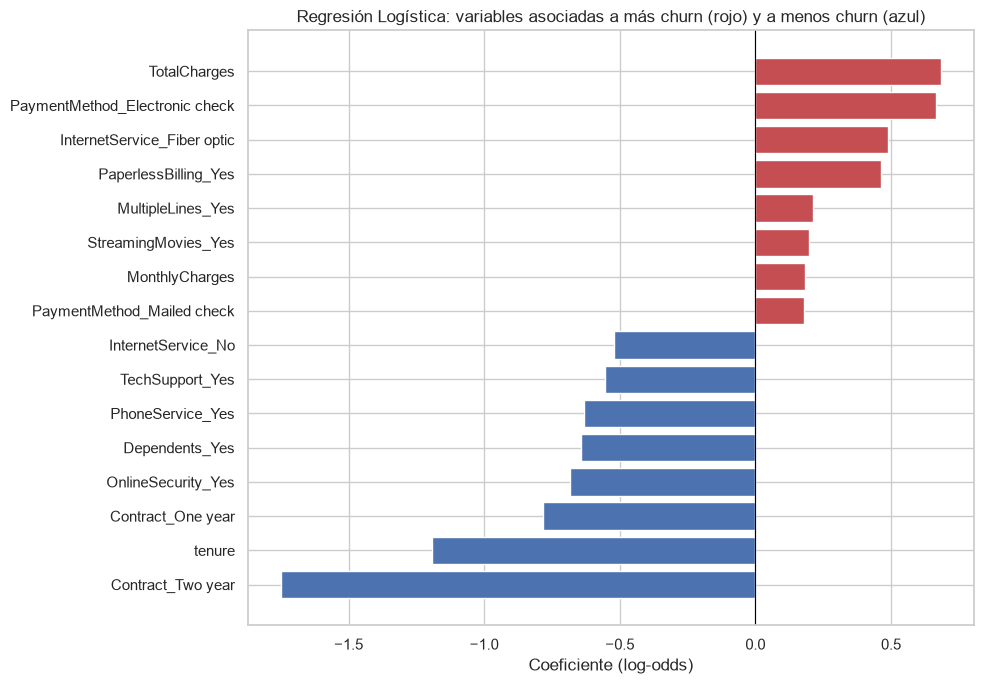

,Variable,Coeficiente,Odds ratio,Comparado contra
0,Contract_Two year,-1.748,0.174,Contract = Month-to-month
1,tenure,-1.191,0.304,aumento de 1 desviación estándar
2,Contract_One year,-0.784,0.456,Contract = Month-to-month
3,OnlineSecurity_Yes,-0.684,0.505,OnlineSecurity = No
4,Dependents_Yes,-0.644,0.525,Dependents = No
5,PhoneService_Yes,-0.633,0.531,PhoneService = No
6,TechSupport_Yes,-0.553,0.575,TechSupport = No
7,InternetService_No,-0.521,0.594,InternetService = DSL
8,OnlineBackup_Yes,-0.249,0.780,OnlineBackup = No
9,SeniorCitizen_Yes,-0.207,0.813,SeniorCitizen = No


In [36]:
pipe_lr = pipelines["Logistic Regression"]
modelo_lr = pipe_lr.named_steps["modelo"]
coefs = pd.DataFrame({"Variable": pipe_lr.named_steps["codificar"].get_feature_names_out(),
                      "Coeficiente": modelo_lr.coef_[0]})
coefs["Odds ratio"] = np.exp(coefs["Coeficiente"])
referencia = dict(zip(CAT_COLS, [c[0] for c in categorias]))
coefs["Comparado contra"] = [
    "aumento de 1 desviación estándar" if v in NUM_COLS
    else f"{v.split('_')[0]} = {referencia[v.split('_')[0]]}" for v in coefs["Variable"]]

top = pd.concat([coefs.nlargest(8, "Coeficiente"), coefs.nsmallest(8, "Coeficiente")]).sort_values("Coeficiente")
plt.figure(figsize=(10, 7))
plt.barh(top["Variable"], top["Coeficiente"], color=["#C44E52" if c > 0 else "#4C72B0" for c in top["Coeficiente"]])
plt.axvline(0, color="black", lw=0.8)
plt.title("Regresión Logística: variables asociadas a más churn (rojo) y a menos churn (azul)")
plt.xlabel("Coeficiente (log-odds)")
plt.tight_layout()
plt.show()

coefs.sort_values("Coeficiente").round(3).reset_index(drop=True)

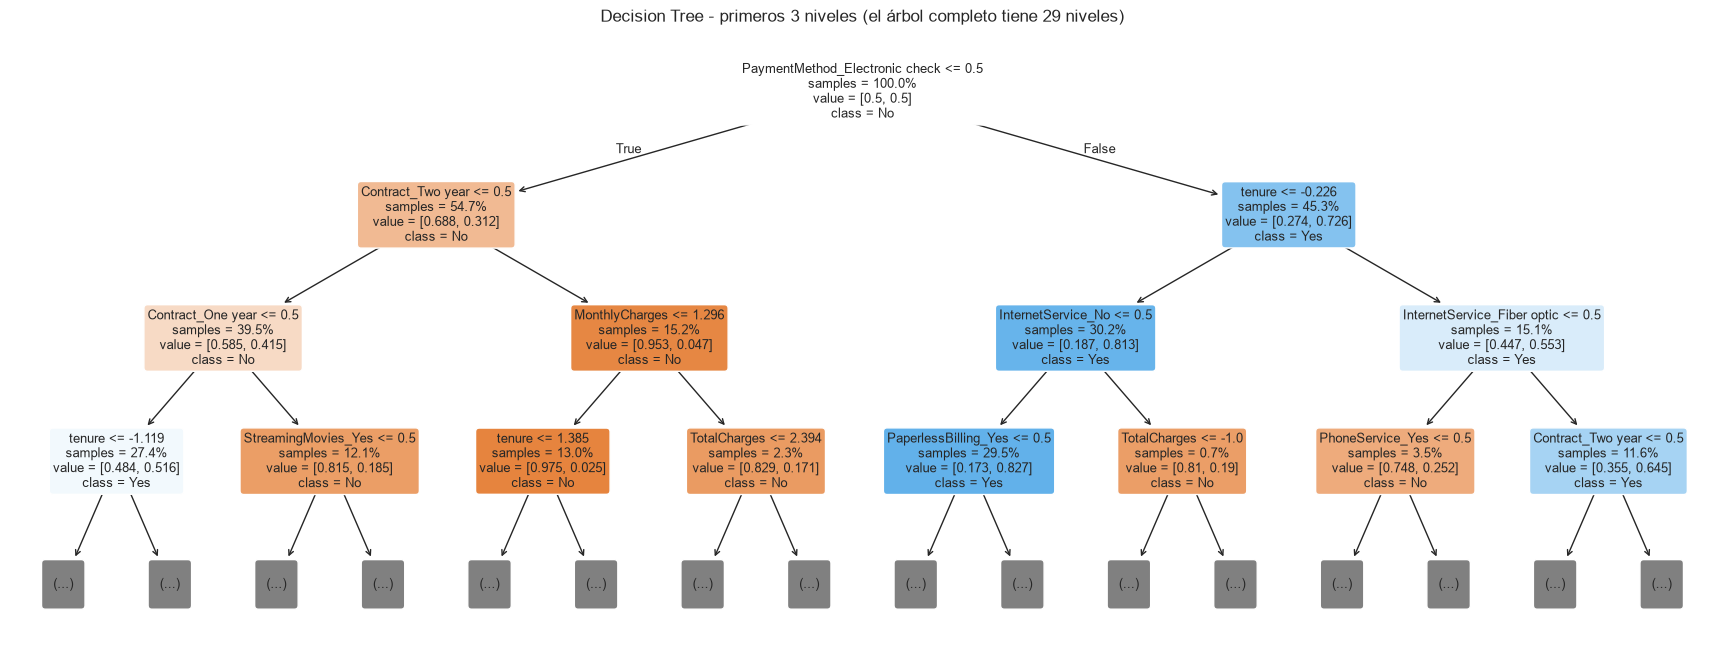

In [37]:
# Para comparar interpretabilidad: primeros niveles del Decision Tree
plt.figure(figsize=(22, 8))
plot_tree(pipelines["Decision Tree"].named_steps["modelo"], max_depth=3,
          feature_names=list(pipelines["Decision Tree"].named_steps["codificar"].get_feature_names_out()),
          class_names=["No", "Yes"], filled=True, rounded=True, fontsize=9, impurity=False, proportion=True)
plt.title("Decision Tree - primeros 3 niveles (el árbol completo tiene 29 niveles)")
plt.show()

### 9.4 Calibración de las probabilidades
El sistema de predicción debe mostrar una "probabilidad de abandono". Pero `predict_proba()` **no garantiza** que esa probabilidad esté calibrada, es decir, que de los clientes a los que el modelo les asigna 70 %, abandone realmente cerca del 70 %. En este caso hay un motivo concreto para dudarlo: el modelo se entrenó con datos balanceados (50 % de churn), así que tiende a **sobreestimar** el riesgo frente a la tasa real de 26,5 %.

Se evalúa y corrige así:
1. **Brier score** (error cuadrático medio de las probabilidades; más bajo es mejor) y **curva de calibración** en el conjunto de prueba.
2. **`CalibratedClassifierCV`** con el método `sigmoid` (Platt): con validación cruzada interna de 5 folds sobre el entrenamiento, aprende una función que transforma la probabilidad del modelo en una probabilidad ajustada a la tasa real. Con `ensemble=False`, el modelo final es el mismo pipeline entrenado con todo el conjunto de entrenamiento, y solo se le agrega la transformación.

La calibración **no cambia el orden** de los clientes (el ROC-AUC es el mismo); solo corrige la escala de las probabilidades.

Tasa real de churn en prueba      : 0.265
Probabilidad promedio sin calibrar: 0.398
Probabilidad promedio calibrada   : 0.269
Brier score sin calibrar          : 0.1675
Brier score calibrado             : 0.1415
ROC-AUC sin calibrar / calibrado  : 0.8327 / 0.8327


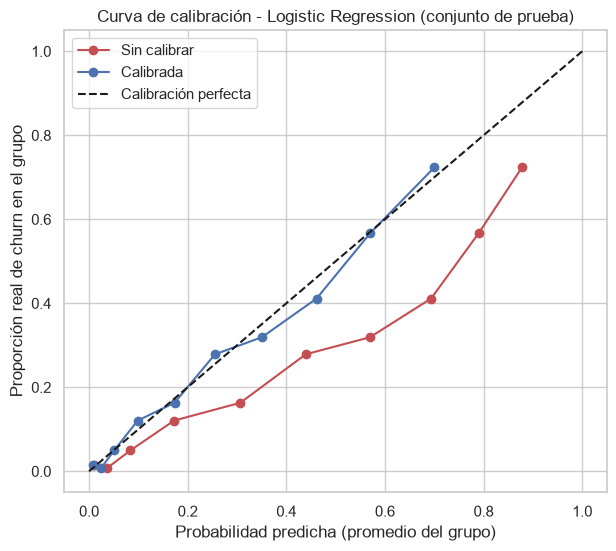

In [38]:
modelo_final = CalibratedClassifierCV(crear_pipeline(modelos[MEJOR]), method="sigmoid", cv=5, ensemble=False)
modelo_final.fit(X_train, y_train)

prob_sin_calibrar = pipelines[MEJOR].predict_proba(X_test)[:, 1]
prob_calibrada = modelo_final.predict_proba(X_test)[:, 1]

print(f"Tasa real de churn en prueba      : {y_test.mean():.3f}")
print(f"Probabilidad promedio sin calibrar: {prob_sin_calibrar.mean():.3f}")
print(f"Probabilidad promedio calibrada   : {prob_calibrada.mean():.3f}")
print(f"Brier score sin calibrar          : {brier_score_loss(y_test, prob_sin_calibrar):.4f}")
print(f"Brier score calibrado             : {brier_score_loss(y_test, prob_calibrada):.4f}")
print(f"ROC-AUC sin calibrar / calibrado  : {roc_auc_score(y_test, prob_sin_calibrar):.4f} / {roc_auc_score(y_test, prob_calibrada):.4f}")

fig, ax = plt.subplots(figsize=(7, 6))
for prob, etiqueta, color in [(prob_sin_calibrar, "Sin calibrar", "#C44E52"), (prob_calibrada, "Calibrada", "#4C72B0")]:
    frac_real, prob_media = calibration_curve(y_test, prob, n_bins=10, strategy="quantile")
    ax.plot(prob_media, frac_real, "o-", label=etiqueta, color=color)
ax.plot([0, 1], [0, 1], "k--", label="Calibración perfecta")
ax.set_xlabel("Probabilidad predicha (promedio del grupo)")
ax.set_ylabel("Proporción real de churn en el grupo")
ax.set_title(f"Curva de calibración - {MEJOR} (conjunto de prueba)")
ax.legend()
plt.show()

### 9.5 Umbral de decisión y niveles de riesgo
El modelo que se evaluó en las secciones 6 a 8 clasifica como "abandona" cuando su probabilidad **sin calibrar** es de 0,5 o más. Como la calibración es una transformación que conserva el orden, ese mismo criterio equivale a un umbral sobre la probabilidad **calibrada**. Se calcula ese umbral equivalente para que la clase predicha sea exactamente la misma que se evaluó (con su Recall de 0,765).

Ese umbral queda por debajo de 50 % a propósito: en retención es preferible avisar de más (falsas alarmas) que dejar escapar clientes (falsos negativos).

Niveles de riesgo (criterio explícito, sobre la probabilidad calibrada):
- **ALTO:** probabilidad de 50 % o más (es más probable que abandone a que se quede).
- **MEDIO:** desde el umbral de decisión hasta 50 % (el modelo lo marca como "abandona", pero con menos certeza).
- **BAJO:** por debajo del umbral de decisión (el modelo lo marca como "continúa").

In [39]:
pipeline_final = modelo_final.calibrated_classifiers_[0].estimator
calibrador = modelo_final.calibrated_classifiers_[0].calibrators[0]
# Si el modelo tiene decision_function, el punto 0.5 sin calibrar corresponde a decision_function = 0
punto_corte = 0.0 if hasattr(pipeline_final, "decision_function") else 0.5
UMBRAL = float(calibrador.predict(np.array([punto_corte]))[0])
print(f"Umbral de decisión sobre la probabilidad calibrada: {UMBRAL:.4f}")

coinciden = ((prob_calibrada >= UMBRAL).astype(int) == pipelines[MEJOR].predict(X_test)).mean()
print(f"Las predicciones coinciden con las del modelo evaluado en el {coinciden:.1%} de los clientes de prueba")


def nivel_riesgo(prob):
    if prob >= 0.5:
        return "ALTO"
    if prob >= UMBRAL:
        return "MEDIO"
    return "BAJO"


niveles_test = pd.Series([nivel_riesgo(p) for p in prob_calibrada], index=y_test.index)
validacion = (pd.DataFrame({"Nivel": niveles_test, "Churn real": y_test})
              .groupby("Nivel")["Churn real"].agg(Clientes="size", Tasa_real_de_churn="mean")
              .reindex(["ALTO", "MEDIO", "BAJO"]))
validacion["Tasa_real_de_churn"] = (validacion["Tasa_real_de_churn"] * 100).round(1).astype(str) + " %"
validacion

Umbral de decisión sobre la probabilidad calibrada: 0.2968
Las predicciones coinciden con las del modelo evaluado en el 100.0% de los clientes de prueba


,Clientes,Tasa_real_de_churn
Nivel,,
ALTO,302,62.3 %
MEDIO,265,37.0 %
BAJO,842,10.5 %


**Lectura:** en el conjunto de prueba, de los clientes clasificados como riesgo **ALTO** abandonó el 62,3 %; en **MEDIO**, el 37,0 %; y en **BAJO**, el 10,5 %. Los niveles separan bien a los clientes: la tasa real de churn baja de forma marcada de un nivel al siguiente.

### 9.6 Guardar el modelo final
Se guarda el modelo calibrado, que incluye el pipeline completo (escalar, SMOTENC, codificar y clasificador). SMOTENC solo actúa al entrenar, así que al predecir el modelo recibe los datos crudos de un cliente y aplica exactamente las mismas transformaciones. También se guardan metadatos (opciones válidas, valores por defecto, umbral y métricas) para el sistema de predicción y la app web.

In [40]:
OPCIONES = {c: sorted(X_train[c].unique().tolist()) for c in CAT_COLS}
VALORES_DEFECTO = {c: X_train[c].mode()[0] for c in CAT_COLS}
VALORES_DEFECTO.update({c: float(X_train[c].median()) for c in NUM_COLS})


def transformar(X_datos):
    # Mismas transformaciones que usa el modelo final (sin SMOTENC, que solo actúa al entrenar)
    return pipeline_final.named_steps["codificar"].transform(pipeline_final.named_steps["escalar"].transform(X_datos))


# Cliente promedio del entrenamiento (en el espacio codificado): punto de comparación de las explicaciones
MEDIA_TRAIN = transformar(X_train).mean(axis=0)

metadata = {
    "modelo": MEJOR,
    "umbral": UMBRAL,
    "niveles": {"ALTO": 0.5, "MEDIO": UMBRAL},
    "num_cols": NUM_COLS,
    "cat_cols": CAT_COLS,
    "defaults": VALORES_DEFECTO,
    "opciones": OPCIONES,
    "rangos": {c: [float(X_train[c].min()), float(X_train[c].max())] for c in NUM_COLS},
    "metricas_test": {k: round(float(v), 4) for k, v in tabla.loc[MEJOR].items()},
    "cv": {n: {m: [round(float(v.mean()), 4), round(float(v.std()), 4)] for m, v in s.items()}
           for n, s in scores_cv.items()},
    "friedman": {m: [round(float(friedman.loc[m, "Chi-cuadrado"]), 3), float(friedman.loc[m, "p-value"])]
                 for m in METRICAS},
    "media_codificada": [float(v) for v in MEDIA_TRAIN],
}

joblib.dump(modelo_final, "modelo_churn.pkl")
with open("metadata_churn.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)
print("Guardados: modelo_churn.pkl y metadata_churn.json")

Guardados: modelo_churn.pkl y metadata_churn.json


## 10. Sistema de predicción de nuevos clientes
El usuario ingresa los datos de un cliente y el sistema devuelve:
- **Probabilidad estimada de abandono** (calibrada, sección 9.4).
- **Clase predicha** (`Churn = Yes` si la probabilidad supera el umbral de decisión).
- **Nivel de riesgo** (ALTO, MEDIO o BAJO, con el criterio de la sección 9.5).
- **Explicación sencilla:** las variables que más subieron y más bajaron el riesgo de ese cliente, comparado con el cliente promedio del entrenamiento. Para cada variable original se suman los aportes (coeficiente por diferencia con el promedio) de todas sus columnas codificadas. Es una descripción de cómo el modelo llegó a su resultado, no una explicación causal. Como `tenure` y `TotalCharges` están muy correlacionadas, a veces una aparece subiendo el riesgo y la otra bajándolo; deben leerse juntas (sección 9.3).

Cómo se preparan los datos:
- El sistema usa el **mismo pipeline entrenado**, así que no se recodifica nada a mano: se le entrega un `DataFrame` con las mismas columnas que en el entrenamiento.
- Las variables que no se ingresan toman el valor más frecuente (categóricas) o la mediana (numéricas) del entrenamiento.
- **`TotalCharges`:** si no se ingresa, se **aproxima** como `tenure * MonthlyCharges`. Es solo una aproximación, porque la facturación histórica real depende de cambios de plan y de cargos variables. El sistema avisa cuando la usa.
- **Validación de entradas:** se rechazan variables desconocidas, categorías que no existen en el entrenamiento y valores numéricos negativos o no numéricos. `No internet service` y `No phone service` se aceptan y se convierten a `No`, igual que en la limpieza.

In [41]:
def preparar_cliente(datos):
    # Valida los datos del cliente y devuelve el DataFrame listo para el modelo
    desconocidas = set(datos) - set(NUM_COLS + CAT_COLS)
    if desconocidas:
        raise ValueError(f"Variables desconocidas: {sorted(desconocidas)}")

    cliente = dict(VALORES_DEFECTO)
    cliente.update(datos)

    # Mismas recodificaciones que en la limpieza (sección 5.1)
    for col in SERVICIOS_INTERNET:
        if cliente[col] == "No internet service" or cliente["InternetService"] == "No":
            cliente[col] = "No"
    if cliente["MultipleLines"] == "No phone service" or cliente["PhoneService"] == "No":
        cliente["MultipleLines"] = "No"

    for col in CAT_COLS:
        if cliente[col] not in OPCIONES[col]:
            raise ValueError(f"Valor no válido para {col}: {cliente[col]!r}. Opciones: {OPCIONES[col]}")

    total_aproximado = "TotalCharges" not in datos
    for col in [c for c in NUM_COLS if not (c == "TotalCharges" and total_aproximado)]:
        try:
            cliente[col] = float(cliente[col])
        except (TypeError, ValueError):
            raise ValueError(f"{col} debe ser numérico, se recibió {cliente[col]!r}") from None
        if cliente[col] < 0:
            raise ValueError(f"{col} no puede ser negativo")
    if total_aproximado:
        cliente["TotalCharges"] = cliente["tenure"] * cliente["MonthlyCharges"]

    return pd.DataFrame([cliente])[NUM_COLS + CAT_COLS], total_aproximado


VARIABLE_ORIGINAL = [n.split("_")[0] for n in pipeline_final.named_steps["codificar"].get_feature_names_out()]


def explicar(X_nuevo, n=3):
    # Aporte de cada variable original al log-odds, frente a un cliente promedio (solo modelos lineales)
    clf = pipeline_final.named_steps["modelo"]
    if not hasattr(clf, "coef_"):
        return None, None
    aporte = pd.Series(clf.coef_[0] * (transformar(X_nuevo)[0] - MEDIA_TRAIN), index=VARIABLE_ORIGINAL)
    aporte = aporte.groupby(level=0).sum()
    fila = X_nuevo.iloc[0]
    aporte.index = [f"{v} = {fila[v]:g}" if v in NUM_COLS else f"{v} = {fila[v]}" for v in aporte.index]
    aporte = aporte.sort_values()
    return aporte[aporte > 0].tail(n)[::-1], aporte[aporte < 0].head(n)


def predecir_cliente(datos):
    X_nuevo, total_aproximado = preparar_cliente(datos)
    prob = float(modelo_final.predict_proba(X_nuevo)[0, 1])
    clase = int(prob >= UMBRAL)
    return {"probabilidad": prob, "clase": clase, "nivel": nivel_riesgo(prob),
            "total_aproximado": total_aproximado, "X": X_nuevo}


MENSAJES = {"ALTO": "Cliente con alta probabilidad de abandono",
            "MEDIO": "Cliente con probabilidad moderada de abandono (supera el umbral de decisión)",
            "BAJO": "Cliente con baja probabilidad de abandono"}


def mostrar_prediccion(datos):
    r = predecir_cliente(datos)
    print("Datos ingresados:")
    for k, v in datos.items():
        print(f"   {k:<16}: {v}")
    print("-" * 64)
    print(f"Predicción: {MENSAJES[r['nivel']]}")
    print(f"Probabilidad estimada: {r['probabilidad']:.0%}")
    print(f"Clase predicha: Churn = {'Yes' if r['clase'] else 'No'} (umbral de decisión {UMBRAL:.0%})")
    print(f"Nivel de riesgo: {r['nivel']}  |  Modelo: {MEJOR} (probabilidades calibradas)")
    sube, baja = explicar(r["X"])
    if sube is not None:
        print("Lo que más sube el riesgo :", ", ".join(sube.index) if len(sube) else "ninguna variable")
        print("Lo que más baja el riesgo :", ", ".join(baja.index) if len(baja) else "ninguna variable")
    if r["total_aproximado"]:
        print("Nota: TotalCharges no se ingresó y se aproximó como tenure * MonthlyCharges.")

### 10.1 Ejemplo del enunciado

In [42]:
cliente_ejemplo = {
    "tenure": 5,
    "MonthlyCharges": 95,
    "Contract": "Month-to-month",
    "TechSupport": "No",
    "InternetService": "Fiber optic",
}
mostrar_prediccion(cliente_ejemplo)

X_ej, _ = preparar_cliente(cliente_ejemplo)
print(f"\nPara comparar: probabilidad sin calibrar = {pipelines[MEJOR].predict_proba(X_ej)[0, 1]:.0%}")

Datos ingresados:
   tenure          : 5
   MonthlyCharges  : 95
   Contract        : Month-to-month
   TechSupport     : No
   InternetService : Fiber optic
----------------------------------------------------------------
Predicción: Cliente con alta probabilidad de abandono
Probabilidad estimada: 72%
Clase predicha: Churn = Yes (umbral de decisión 30%)
Nivel de riesgo: ALTO  |  Modelo: Logistic Regression (probabilidades calibradas)
Lo que más sube el riesgo : tenure = 5, Contract = Month-to-month, PaymentMethod = Electronic check
Lo que más baja el riesgo : TotalCharges = 475, MultipleLines = No, StreamingMovies = No
Nota: TotalCharges no se ingresó y se aproximó como tenure * MonthlyCharges.

Para comparar: probabilidad sin calibrar = 89%


**Sobre el 89 % del enunciado:** la probabilidad **sin calibrar** del modelo para este cliente es 89 %, igual que la salida esperada del enunciado. Sin embargo, esa cifra viene de un modelo entrenado con datos balanceados y sobreestima el riesgo. La probabilidad **calibrada**, que es la que se reporta, es de aprox. 72 %. Las dos versiones coinciden en lo importante: el cliente queda en riesgo **ALTO** y la clase predicha es `Churn = Yes`. El perfil (cliente nuevo, contrato mes a mes, fibra óptica, sin soporte técnico) coincide con el de mayor churn en el EDA.

In [43]:
# Varios perfiles para comparar
perfiles = {
    "Ejemplo del enunciado": cliente_ejemplo,
    "Cliente fiel (2 años)": {"tenure": 60, "MonthlyCharges": 65, "Contract": "Two year",
                              "TechSupport": "Yes", "InternetService": "DSL",
                              "PaymentMethod": "Bank transfer (automatic)"},
    "Cliente nuevo sin internet": {"tenure": 2, "MonthlyCharges": 20, "Contract": "Month-to-month",
                                   "TechSupport": "No internet service", "InternetService": "No"},
    "Fibra + contrato anual": {"tenure": 24, "MonthlyCharges": 90, "Contract": "One year",
                               "TechSupport": "Yes", "InternetService": "Fiber optic"},
}
filas = []
for nombre, datos in perfiles.items():
    r = predecir_cliente(datos)
    filas.append({"Perfil": nombre, "Probabilidad calibrada": f"{r['probabilidad']:.0%}",
                  "Clase predicha": "Yes (abandona)" if r["clase"] else "No (continúa)", "Riesgo": r["nivel"]})
pd.DataFrame(filas).set_index("Perfil")

,Probabilidad calibrada,Clase predicha,Riesgo
Perfil,,,
Ejemplo del enunciado,72%,Yes (abandona),ALTO
Cliente fiel (2 años),3%,No (continúa),BAJO
Cliente nuevo sin internet,42%,Yes (abandona),MEDIO
Fibra + contrato anual,35%,Yes (abandona),MEDIO


### 10.2 Manejo de entradas inválidas
Antes de predecir, el sistema valida los datos. Estos son tres ejemplos de entradas que se rechazan con un mensaje claro en vez de producir una predicción sin sentido:

In [44]:
pruebas_invalidas = [
    {"tenure": -3, "MonthlyCharges": 70},
    {"tenure": 12, "MonthlyCharges": 70, "Contract": "Mensual"},
    {"tenure": 12, "MonthlyCharges": "setenta"},
]
for datos in pruebas_invalidas:
    try:
        predecir_cliente(datos)
        print("Aceptada:", datos)
    except ValueError as e:
        print(f"Rechazada {datos}\n   -> {e}")

Rechazada {'tenure': -3, 'MonthlyCharges': 70}
   -> tenure no puede ser negativo
Rechazada {'tenure': 12, 'MonthlyCharges': 70, 'Contract': 'Mensual'}
   -> Valor no válido para Contract: 'Mensual'. Opciones: ['Month-to-month', 'One year', 'Two year']
Rechazada {'tenure': 12, 'MonthlyCharges': 'setenta'}
   -> MonthlyCharges debe ser numérico, se recibió 'setenta'


### 10.3 Formulario interactivo (ingreso manual)
**Ejecute la celda** para que aparezca el formulario. Luego ajuste los valores y presione **Predecir**. Las variables adicionales están en el desplegable "Otras variables". Si `TotalCharges` se deja en 0, se aproxima como `tenure * MonthlyCharges`.

In [45]:
import ipywidgets as widgets
from IPython.display import display, clear_output

estilo = {"description_width": "150px"}
ancho = widgets.Layout(width="420px")

w_tenure = widgets.IntSlider(value=5, min=0, max=72, description="Tenure (meses)", style=estilo, layout=ancho)
w_monthly = widgets.FloatSlider(value=95, min=18, max=120, step=0.5, description="MonthlyCharges", style=estilo, layout=ancho)
w_total = widgets.FloatText(value=0, description="TotalCharges", style=estilo, layout=ancho)
principales = ["Contract", "TechSupport", "InternetService"]
valores_iniciales = {"Contract": "Month-to-month", "TechSupport": "No", "InternetService": "Fiber optic"}
w_cat = {c: widgets.Dropdown(options=OPCIONES[c], value=valores_iniciales.get(c, VALORES_DEFECTO[c]),
                             description=c, style=estilo, layout=ancho) for c in CAT_COLS}

otras = widgets.VBox([w_total] + [w_cat[c] for c in CAT_COLS if c not in principales])
acordeon = widgets.Accordion(children=[otras])
acordeon.set_title(0, "Otras variables (opcional)")

boton = widgets.Button(description="Predecir", button_style="primary", icon="search")
salida = widgets.Output()


def al_predecir(_):
    datos = {"tenure": w_tenure.value, "MonthlyCharges": w_monthly.value}
    datos.update({c: w.value for c, w in w_cat.items()})
    if w_total.value > 0:
        datos["TotalCharges"] = w_total.value
    with salida:
        clear_output()
        try:
            mostrar_prediccion(datos)
        except ValueError as e:
            print("Entrada no válida:", e)


boton.on_click(al_predecir)
display(widgets.VBox([widgets.HTML("<h3>Predicción de Churn - Nuevo cliente</h3>"),
                      w_tenure, w_monthly, *[w_cat[c] for c in principales], acordeon, boton, salida]))

## 11. Preguntas de interpretación de métricas

### 11.1 Accuracy
**¿Qué significa obtener un Accuracy de 85 %?**
Que de cada 100 clientes el modelo clasifica bien a 85, sumando los aciertos de ambas clases (los que abandonan y los que no). Solo cuenta aciertos totales: no dice en qué clase se equivoca. El modelo elegido obtuvo aprox. 74 % en prueba.

**¿Puede un Accuracy alto ser engañoso?**
Sí. En este dataset un modelo que siempre responda "No abandona" logra **73,5 % de Accuracy** con **Recall = 0**: no detecta a ningún cliente que se va. En nuestros resultados, SVM tiene **más Accuracy (0,754) que la Regresión Logística (0,738)**, pero detecta **18 clientes que abandonan menos**. Para el objetivo de retención, el modelo con menor Accuracy es el más útil.

**¿Qué ocurre si las clases están desbalanceadas?**
El Accuracy queda dominado por la clase mayoritaria y el modelo aprende a predecir casi siempre "No". Por eso: (1) se estratificó la división, (2) se balanceó el entrenamiento con SMOTENC y (3) se priorizaron Recall, Precision, F1 y ROC-AUC de la clase `Churn = Yes`. En la sección 5.6 se ve el efecto: sin balanceo el Recall cae a 0,54.

### 11.2 Precision
**¿Qué interpreta de una Precision alta en churn?**
Que cuando el modelo marca a un cliente como "abandonará", casi siempre acierta: las alertas son **confiables**. La Regresión Logística tiene una Precision de aprox. 0,50, así que 1 de cada 2 alertas corresponde a un cliente que realmente abandonó.

**¿Qué significa identificar incorrectamente clientes que NO abandonarán?**
Son los **Falsos Positivos (FP)**: clientes que se iban a quedar, pero el modelo dijo que se irían. Consecuencias: se gasta presupuesto de retención (descuentos, llamadas, regalos) en quien no lo necesitaba, se regalan descuentos que reducen ingresos, y se puede molestar al cliente con contactos innecesarios. La Regresión Logística tuvo unos 281 FP en prueba.

**¿Por qué marketing podría necesitar alta Precision?**
Porque el **presupuesto es limitado** y cada oferta de retención cuesta dinero. Con alta Precision, cada peso invertido llega a un cliente que realmente estaba en riesgo, lo que mejora el retorno de la campaña. Si la acción es barata (un correo), se tolera una Precision baja. Si es cara (un descuento grande o un equipo nuevo), conviene **subir el umbral** de decisión para ganar Precision, aceptando perder algo de Recall.

### 11.3 Recall
**¿Por qué Recall es importante en retención de clientes?**
Porque mide **qué porcentaje de los clientes que realmente se van detecta el modelo**. Un cliente no detectado no recibe ninguna acción de retención. La Regresión Logística tiene un Recall de 0,765 en prueba: detecta aprox. **3 de cada 4** clientes que abandonan.

**¿Qué impacto tiene un falso negativo?**
Un **FN** es un cliente que abandona sin que el modelo lo haya alertado. La empresa deja de recibir su factura mensual (en promedio 74,44 u.m. entre los que abandonaron) y sus ingresos futuros, y no tuvo oportunidad de intentar retenerlo. En churn, un FN suele ser **más costoso que un FP**, siempre que la oferta de retención cueste menos que el valor del cliente. La Regresión Logística tuvo 88 FN en prueba; el Decision Tree, 152.

**¿Qué ocurre si el modelo no detecta clientes próximos a abandonar?**
El abandono es "silencioso": la empresa se entera cuando el cliente ya se fue y no hay oportunidad de retenerlo. El sistema pierde su razón de ser. Por ejemplo, el Decision Tree dejó escapar el **41 %** de los clientes que abandonaron.

### 11.4 F1-Score
**¿Por qué F1-Score es importante en problemas empresariales?**
Porque es la **media armónica de Precision y Recall**, así que resume en un solo número el equilibrio entre dos costos reales: las falsas alarmas (dinero gastado en campañas) y los clientes perdidos sin aviso. Con clases desbalanceadas, donde el Accuracy engaña, el F1 es más representativo. Por eso fue una de las métricas principales de las pruebas estadísticas.

**¿Qué indica un F1-Score bajo?**
Que el modelo falla en al menos una de las dos: genera muchas falsas alarmas, deja escapar muchos clientes que abandonan, o ambas cosas. El Decision Tree tiene F1 = 0,527 porque tanto su Precision (0,473) como su Recall (0,594) son bajas.

**¿Qué sucede si Precision y Recall son muy diferentes?**
La media armónica castiga el desequilibrio: el F1 queda cerca del **valor más bajo** de los dos. Un ejemplo real de la sección 5.6: la Regresión Logística **sin balanceo** tiene Precision de 0,65 pero Recall de 0,54, y su F1 (0,59) queda por debajo del de la versión balanceada (0,63), que tiene ambas métricas más parejas. Esa diferencia también indica que se puede **mover el umbral** para equilibrar ambas métricas según la estrategia del negocio.

### 11.5 ROC-AUC
**¿Qué significa un ROC-AUC cercano a 1?**
Que el modelo **distingue casi perfectamente** entre clientes que abandonan y clientes que se quedan. El AUC es la probabilidad de que, tomando al azar un cliente que abandona y uno que no, el modelo le asigne mayor riesgo al que realmente abandona. **0,5 = azar** (la línea diagonal) y **1,0 = discriminación perfecta**. No depende del umbral elegido.

La Regresión Logística tiene **AUC = 0,833** en prueba: ordena correctamente aprox. el 83 % de los pares, lo cual es útil para **ordenar a los clientes por riesgo** y priorizar campañas. El Decision Tree, con 0,678, está mucho más cerca del azar. Un AUC alto no garantiza que las probabilidades estén bien calibradas (eso se revisó en la sección 9.4).

## 12. Preguntas de análisis crítico
### ¿Qué modelo fue más interpretable?
**La Regresión Logística.** Cada coeficiente indica la dirección y la magnitud de la asociación, y sus *odds ratios* se explican frente a una categoría de referencia (sección 9.3). Por ejemplo, manteniendo lo demás igual:
- `Contract = Two year` frente a `Month-to-month`: odds ratio de aprox. **0,17** (odds de abandonar un 83 % menores).
- `Contract = One year` frente a `Month-to-month`: odds ratio de aprox. **0,46**.
- `PaymentMethod = Electronic check` frente a `Bank transfer (automatic)`: odds ratio de aprox. **1,94**.
- `InternetService = Fiber optic` frente a `DSL`: odds ratio de aprox. **1,63**.
- `OnlineSecurity = Yes` frente a `No`: odds ratio de aprox. **0,51**; `TechSupport = Yes` frente a `No`: aprox. **0,58**.

Estas son asociaciones dentro del modelo, no efectos causales.

El **Decision Tree** también es interpretable en teoría (reglas si-entonces), pero sin podar tiene **29 niveles y 1.433 hojas**, imposible de leer en la práctica. Naive Bayes es intermedio. **KNN** y **SVM con kernel RBF** son cajas negras.

### ¿Cuál presentó mayor riesgo de overfitting?
**El Decision Tree, por mucho.** Obtuvo **F1 = 0,996 y AUC = 1,000 en entrenamiento**, pero **F1 = 0,527 y AUC = 0,678 en prueba**. Sin límite de profundidad, el árbol creció hasta memorizar a cada cliente, incluidos los ejemplos sintéticos de SMOTENC.

En segundo lugar quedó **KNN** (brecha de AUC de aprox. 0,15): con k = 5, cada predicción depende de muy pocos vecinos. La Regresión Logística y Naive Bayes casi no sobreajustan (brechas de 0,01 a 0,02).

**Cómo se podría mitigar:** podar el árbol (`max_depth`, `min_samples_leaf`, `ccp_alpha`), aumentar k en KNN y ajustar hiperparámetros con validación cruzada (`GridSearchCV`). No se hizo en este trabajo para comparar los 5 modelos con su configuración por defecto.

## 13. Conclusiones empresariales y limitaciones
### Conclusiones
1. **El churn es relevante para el negocio:** 1 de cada 4 clientes abandonó (26,5 %), y esos clientes representaban el **30,5 % de la facturación mensual** (139.130,85 u.m. al mes).
2. **Perfil asociado a mayor abandono:** clientes con **menos de 12 meses**, **contrato mes a mes**, **fibra óptica**, **sin soporte técnico ni seguridad en línea**, que pagan con **cheque electrónico**.
3. **Modelo recomendado: Regresión Logística con probabilidades calibradas.** Detecta aprox. **3 de cada 4** clientes que abandonan (Recall de 0,765 en prueba), tiene el mejor ROC-AUC (0,833 en prueba, 0,842 en CV) y se puede explicar a las áreas de negocio. Su ventaja frente a SVM y Naive Bayes es clara en ROC-AUC, pero no en F1.
4. **Segmentación útil:** con las probabilidades calibradas, el segmento ALTO tuvo un 62,3 % de churn real en prueba, el MEDIO un 37,0 % y el BAJO un 10,5 %. Eso permite asignar acciones distintas a cada segmento.

### Recomendaciones (para probar, no garantizadas)
Las variables asociadas al churn sugieren dónde actuar, pero el modelo no prueba que estas acciones reduzcan el abandono. Lo recomendable es probarlas con un grupo de control:
- **Migración de contratos:** ofrecer un incentivo para pasar de mes a mes a contratos de 1 o 2 años al segmento ALTO.
- **Acompañamiento en el primer año:** contacto y soporte proactivo durante los primeros 12 meses.
- **Soporte y seguridad:** ofrecer `TechSupport` u `OnlineSecurity` por algunos meses a clientes de fibra en riesgo.
- **Pago automático:** incentivar el cambio del cheque electrónico a pago automático.
- **Revisar la fibra óptica:** investigar si el abandono se debe al precio, a la calidad o a la competencia.

### Escenario ilustrativo (no es un resultado medido)
Supuestos: el modelo detecta el 76,5 % de los clientes que abandonan (su Recall en prueba), la campaña retiene al **25 %** de los detectados (valor hipotético) y cada cliente retenido paga 12 meses más su factura promedio (74,44 u.m.). Con los 1.869 clientes que abandonaron:

1.869 x 0,765 x 0,25 = aprox. 357 clientes retenidos, es decir, aprox. **319.000 u.m. de facturación anual** potencialmente recuperable.

Esta cifra es **bruta**: no descuenta el costo de la campaña ni el de las ofertas entregadas a falsos positivos (unos 281 en una muestra de 1.409 clientes). Para estimar un beneficio real habría que conocer esos costos y medir la tasa de retención real con una prueba controlada.

### Limitaciones del trabajo
- **Un solo corte de datos:** el dataset es una foto de un momento; no hay fechas, así que no se puede validar el modelo en un periodo posterior.
- **Sin costos:** no hay información de costos de adquisición, de campañas ni de márgenes, por lo que no se puede calcular la pérdida económica neta ni el umbral óptimo por costo.
- **Moneda no especificada:** los montos se expresan en unidades monetarias (u.m.).
- **Asociación, no causalidad:** las variables importantes indican dónde investigar, no qué causa el abandono.
- **Hiperparámetros por defecto:** ningún modelo se ajustó; los resultados de KNN y Decision Tree en particular podrían mejorar.
- **Pruebas estadísticas con 10 folds:** las comparaciones tienen poca potencia para detectar diferencias pequeñas entre los 3 mejores modelos.

## 14. Despliegue web (Streamlit)
Como complemento, el modelo seleccionado se publicó en una aplicación web con **Streamlit**. En ella, una persona del área de negocio puede ingresar los datos de un cliente desde el navegador, sin abrir Python.

- **App:** [churn-telco-prediccion.streamlit.app](https://churn-telco-prediccion.streamlit.app/)
- **Repositorio:** [github.com/jamn95/churn-telco](https://github.com/jamn95/churn-telco)

La app usa los mismos archivos que genera este cuaderno (`modelo_churn.pkl` y `metadata_churn.json`).